In [1]:
import pandas as pd

df = pd.read_pickle("data/interactions_with_sequences_RNA_RNA_15-03-2026.pkl")


In [2]:
df.keys()

Index(['RNAInterID', 'Interactor1.Symbol', 'Category1', 'Species1',
       'Interactor2.Symbol', 'Category2', 'Species2', 'Raw_ID1', 'Raw_ID2',
       'score', 'strong', 'weak', 'predict', 'Species1_TaxID',
       'Species2_TaxID', 'key1', 'key2', 'ent1_ID_buckets', 'ent1_sequences',
       'ent1_typecheck', 'ent1_GO_RNAcentral', 'ent1_Rfam', 'ent1_GO_raw',
       'ent1_mygene_raw', 'ent1_Raw_key', 'ent2_ID_buckets', 'ent2_sequences',
       'ent2_typecheck', 'ent2_GO_RNAcentral', 'ent2_Rfam', 'ent2_GO_raw',
       'ent2_mygene_raw', 'ent2_Raw_key'],
      dtype='object')

In [3]:
# remove mRNA-entities:
print(len(df))
df = df[
    (df["Category1"] != "mRNA") &
    (df["Category2"] != "mRNA")
]
print(len(df))

7449338
119365


Shape: (119365, 36)
Final dataset size: 118941
Types retained: 16
Species pairs retained: 27


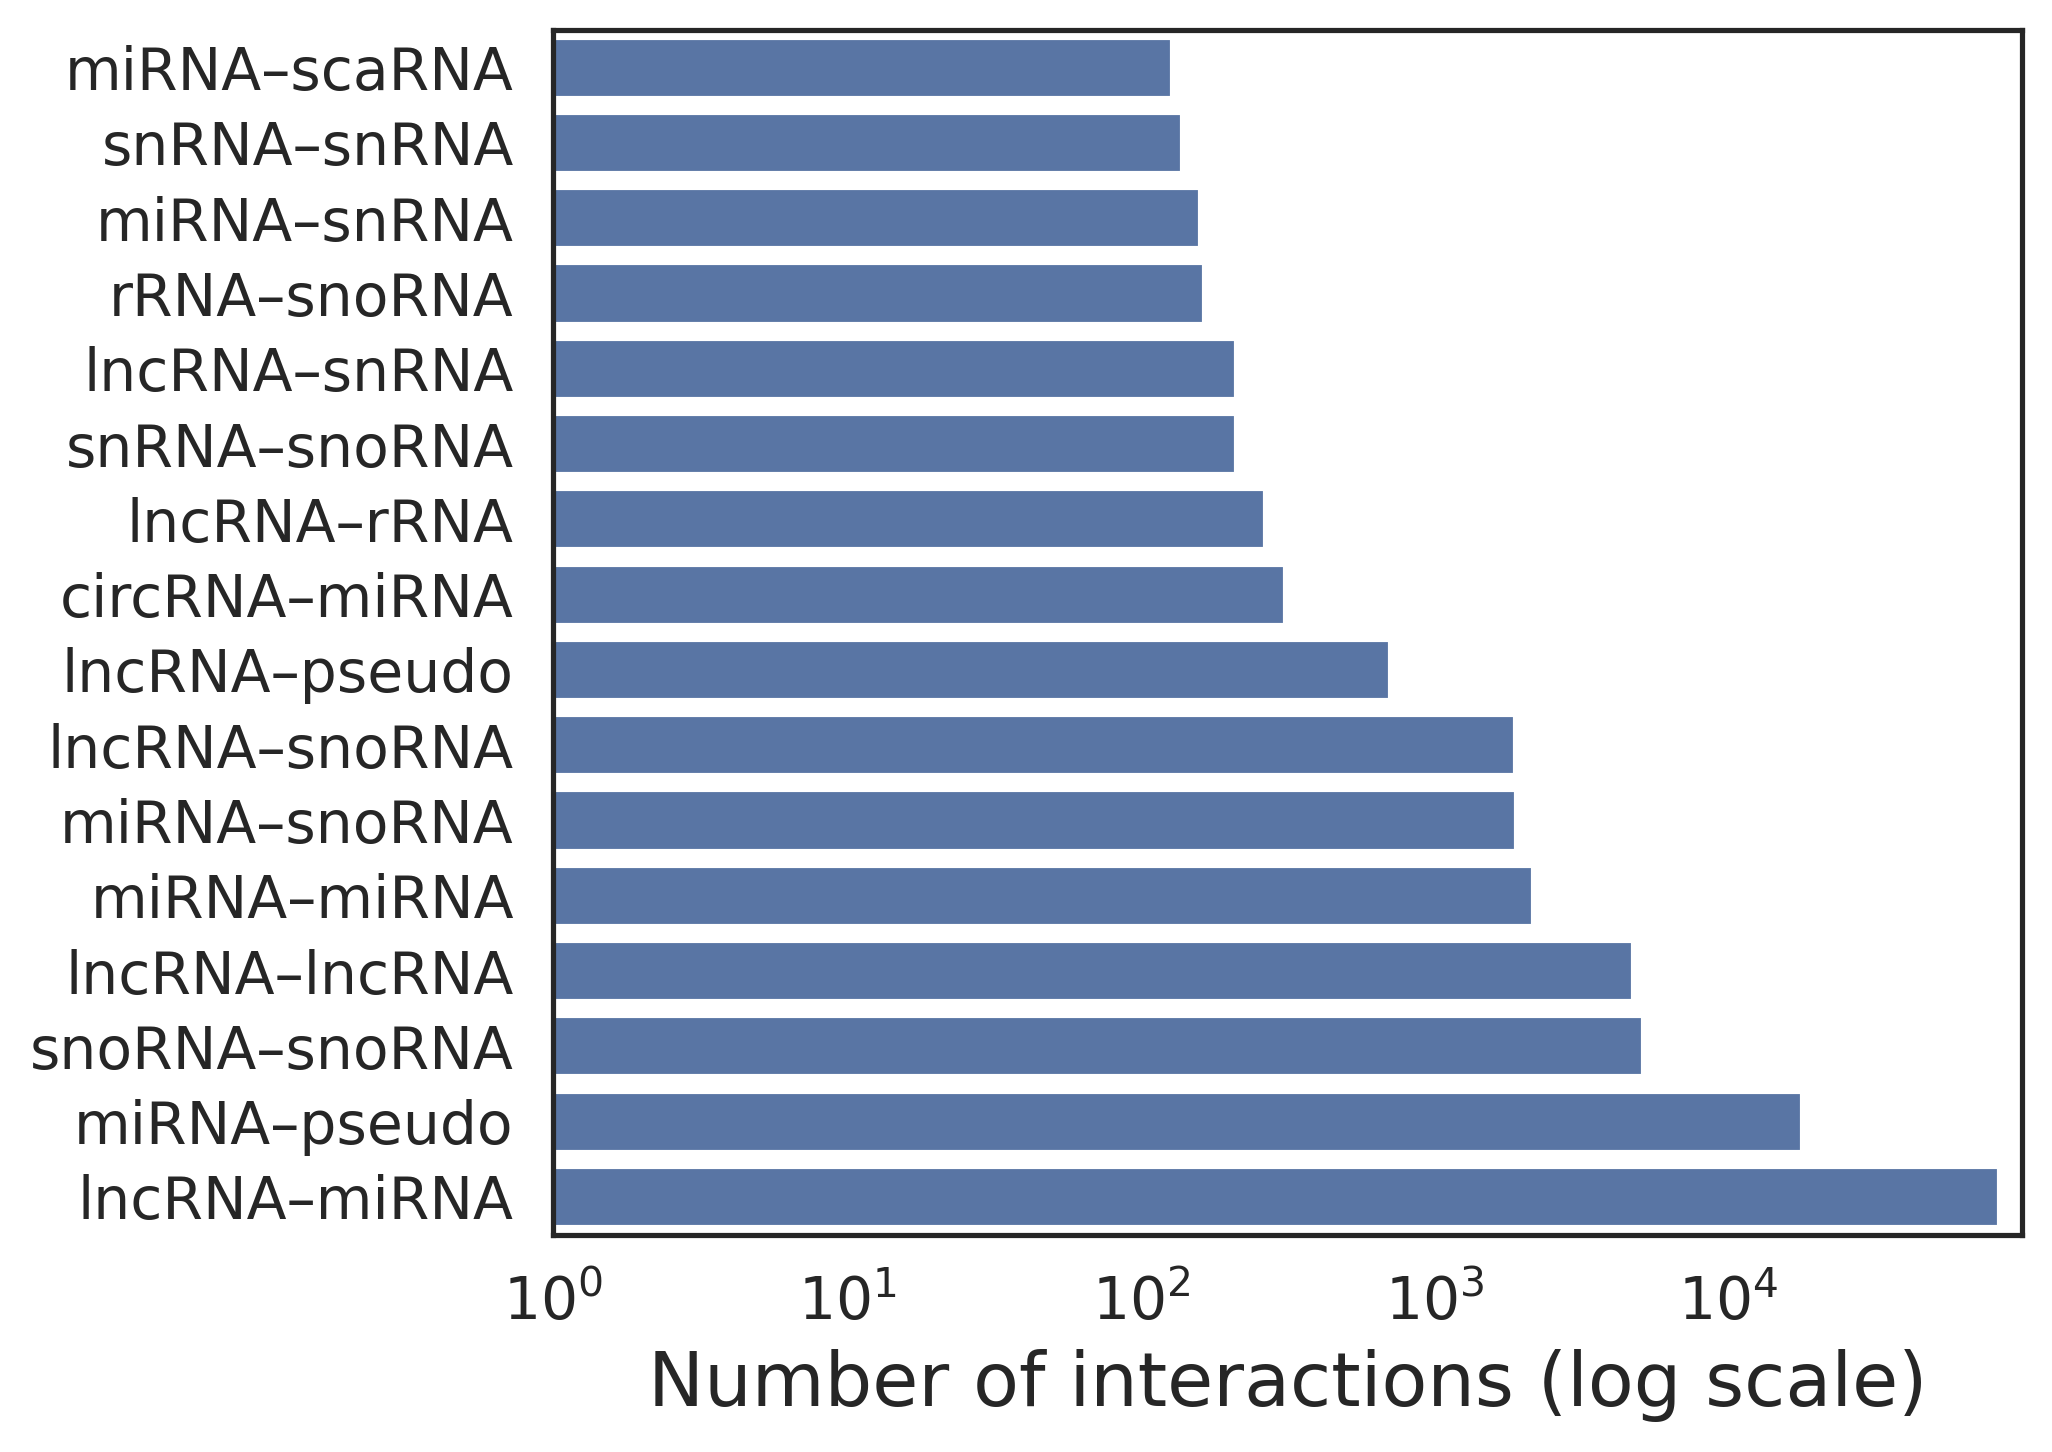

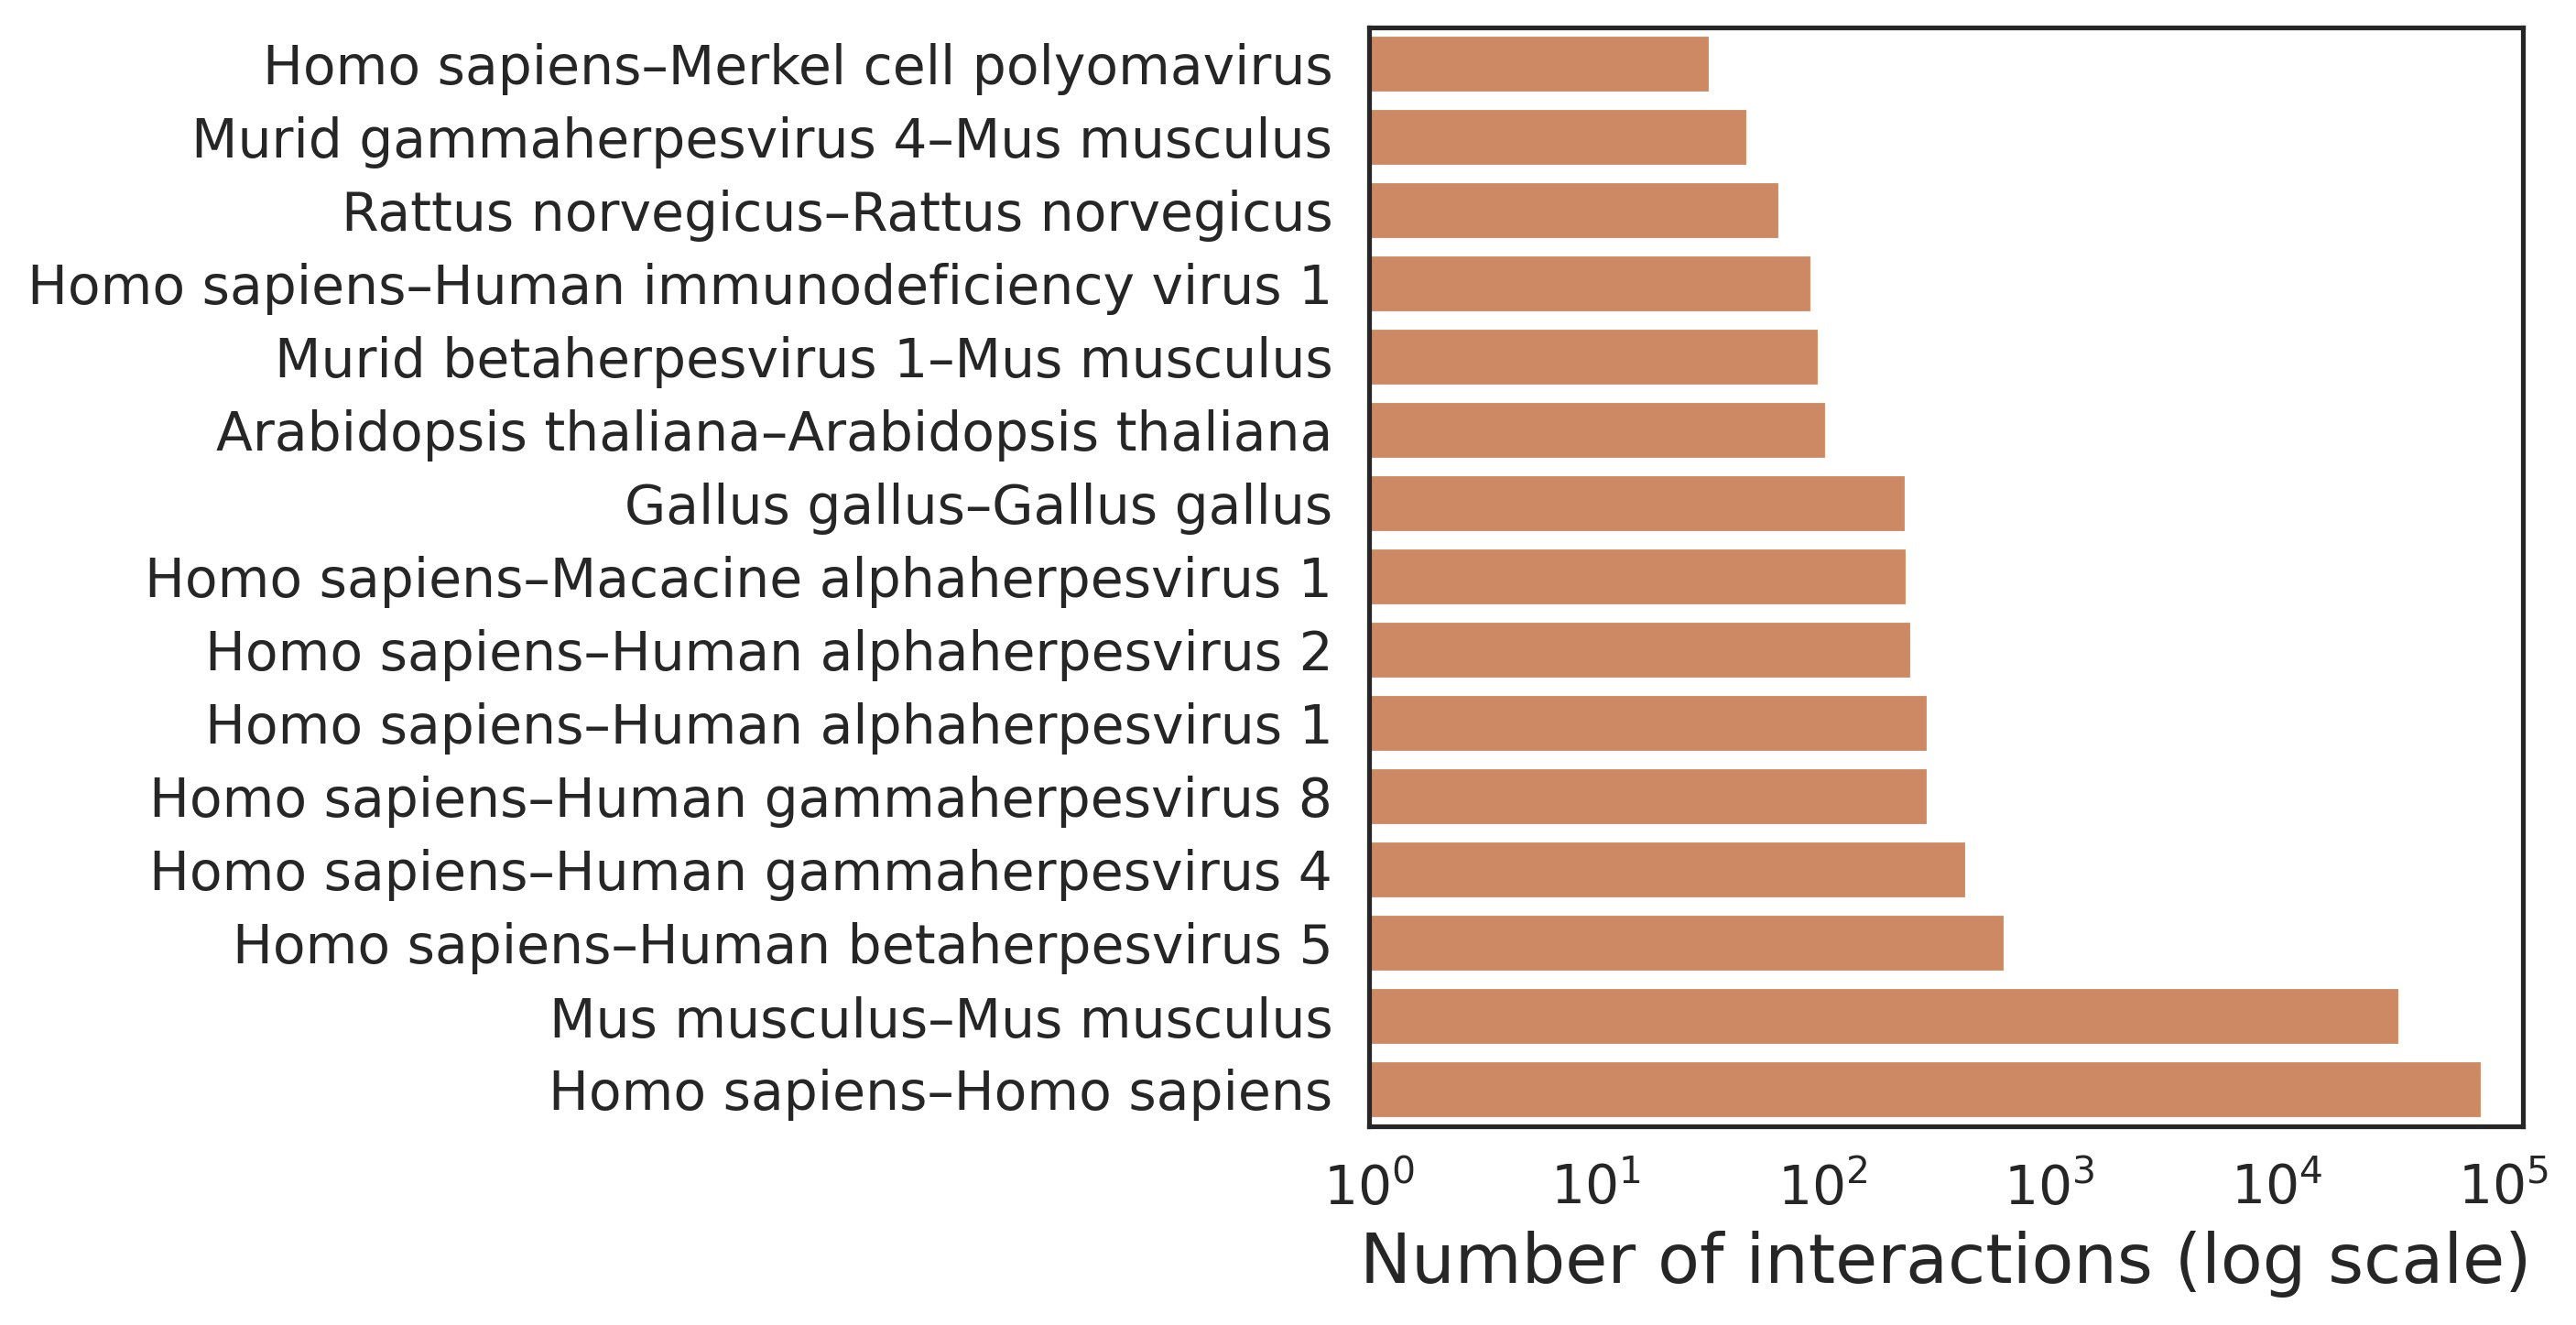

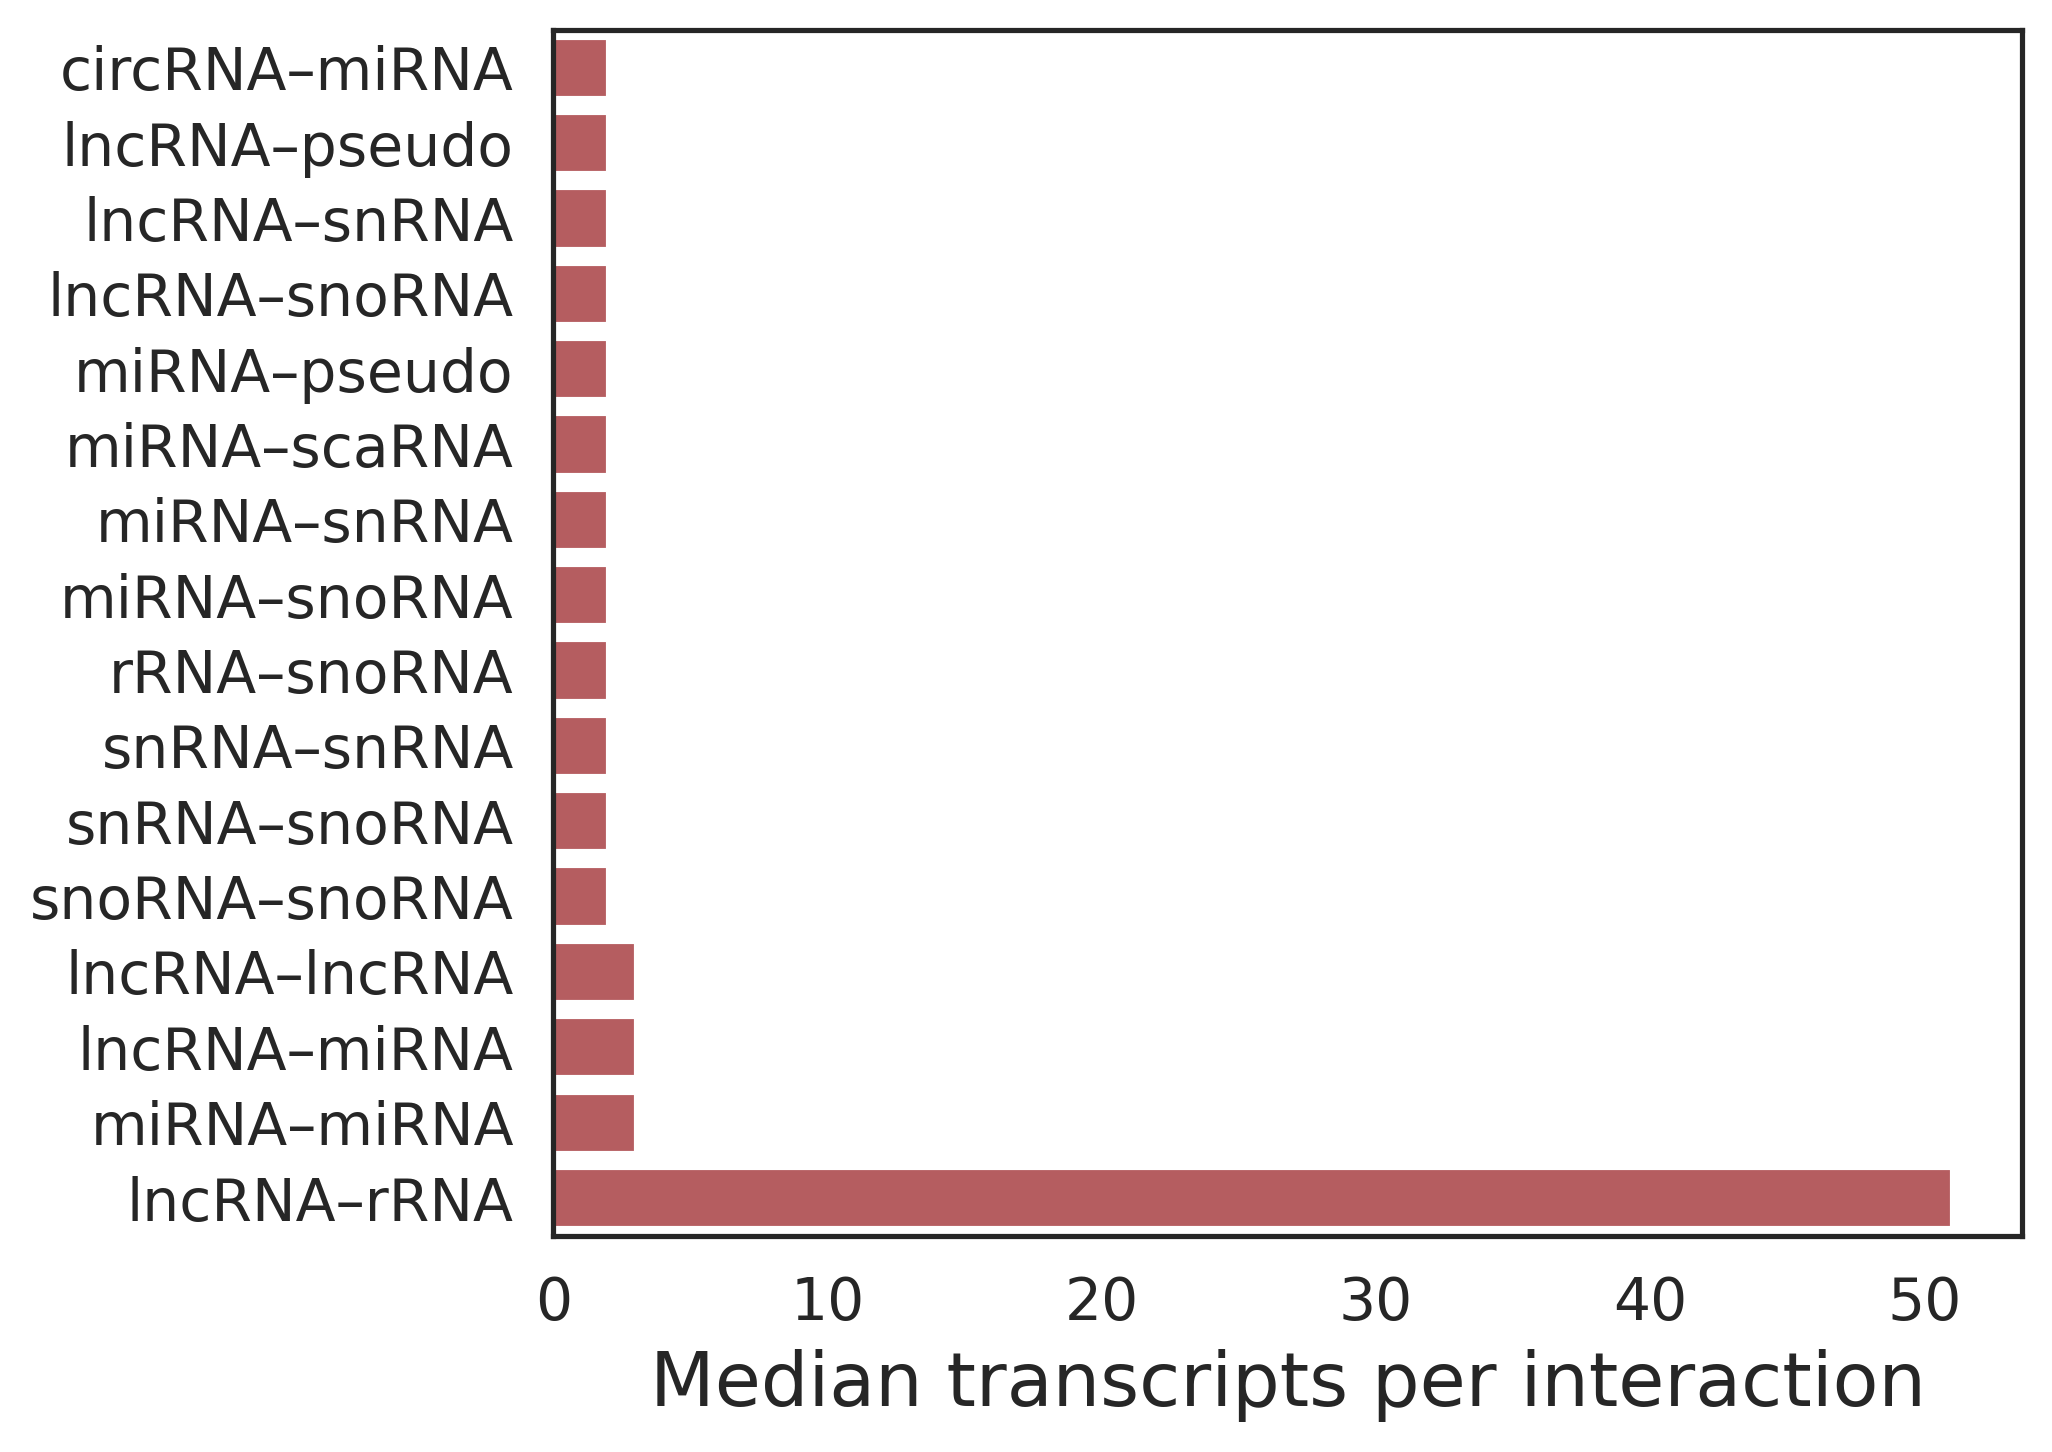

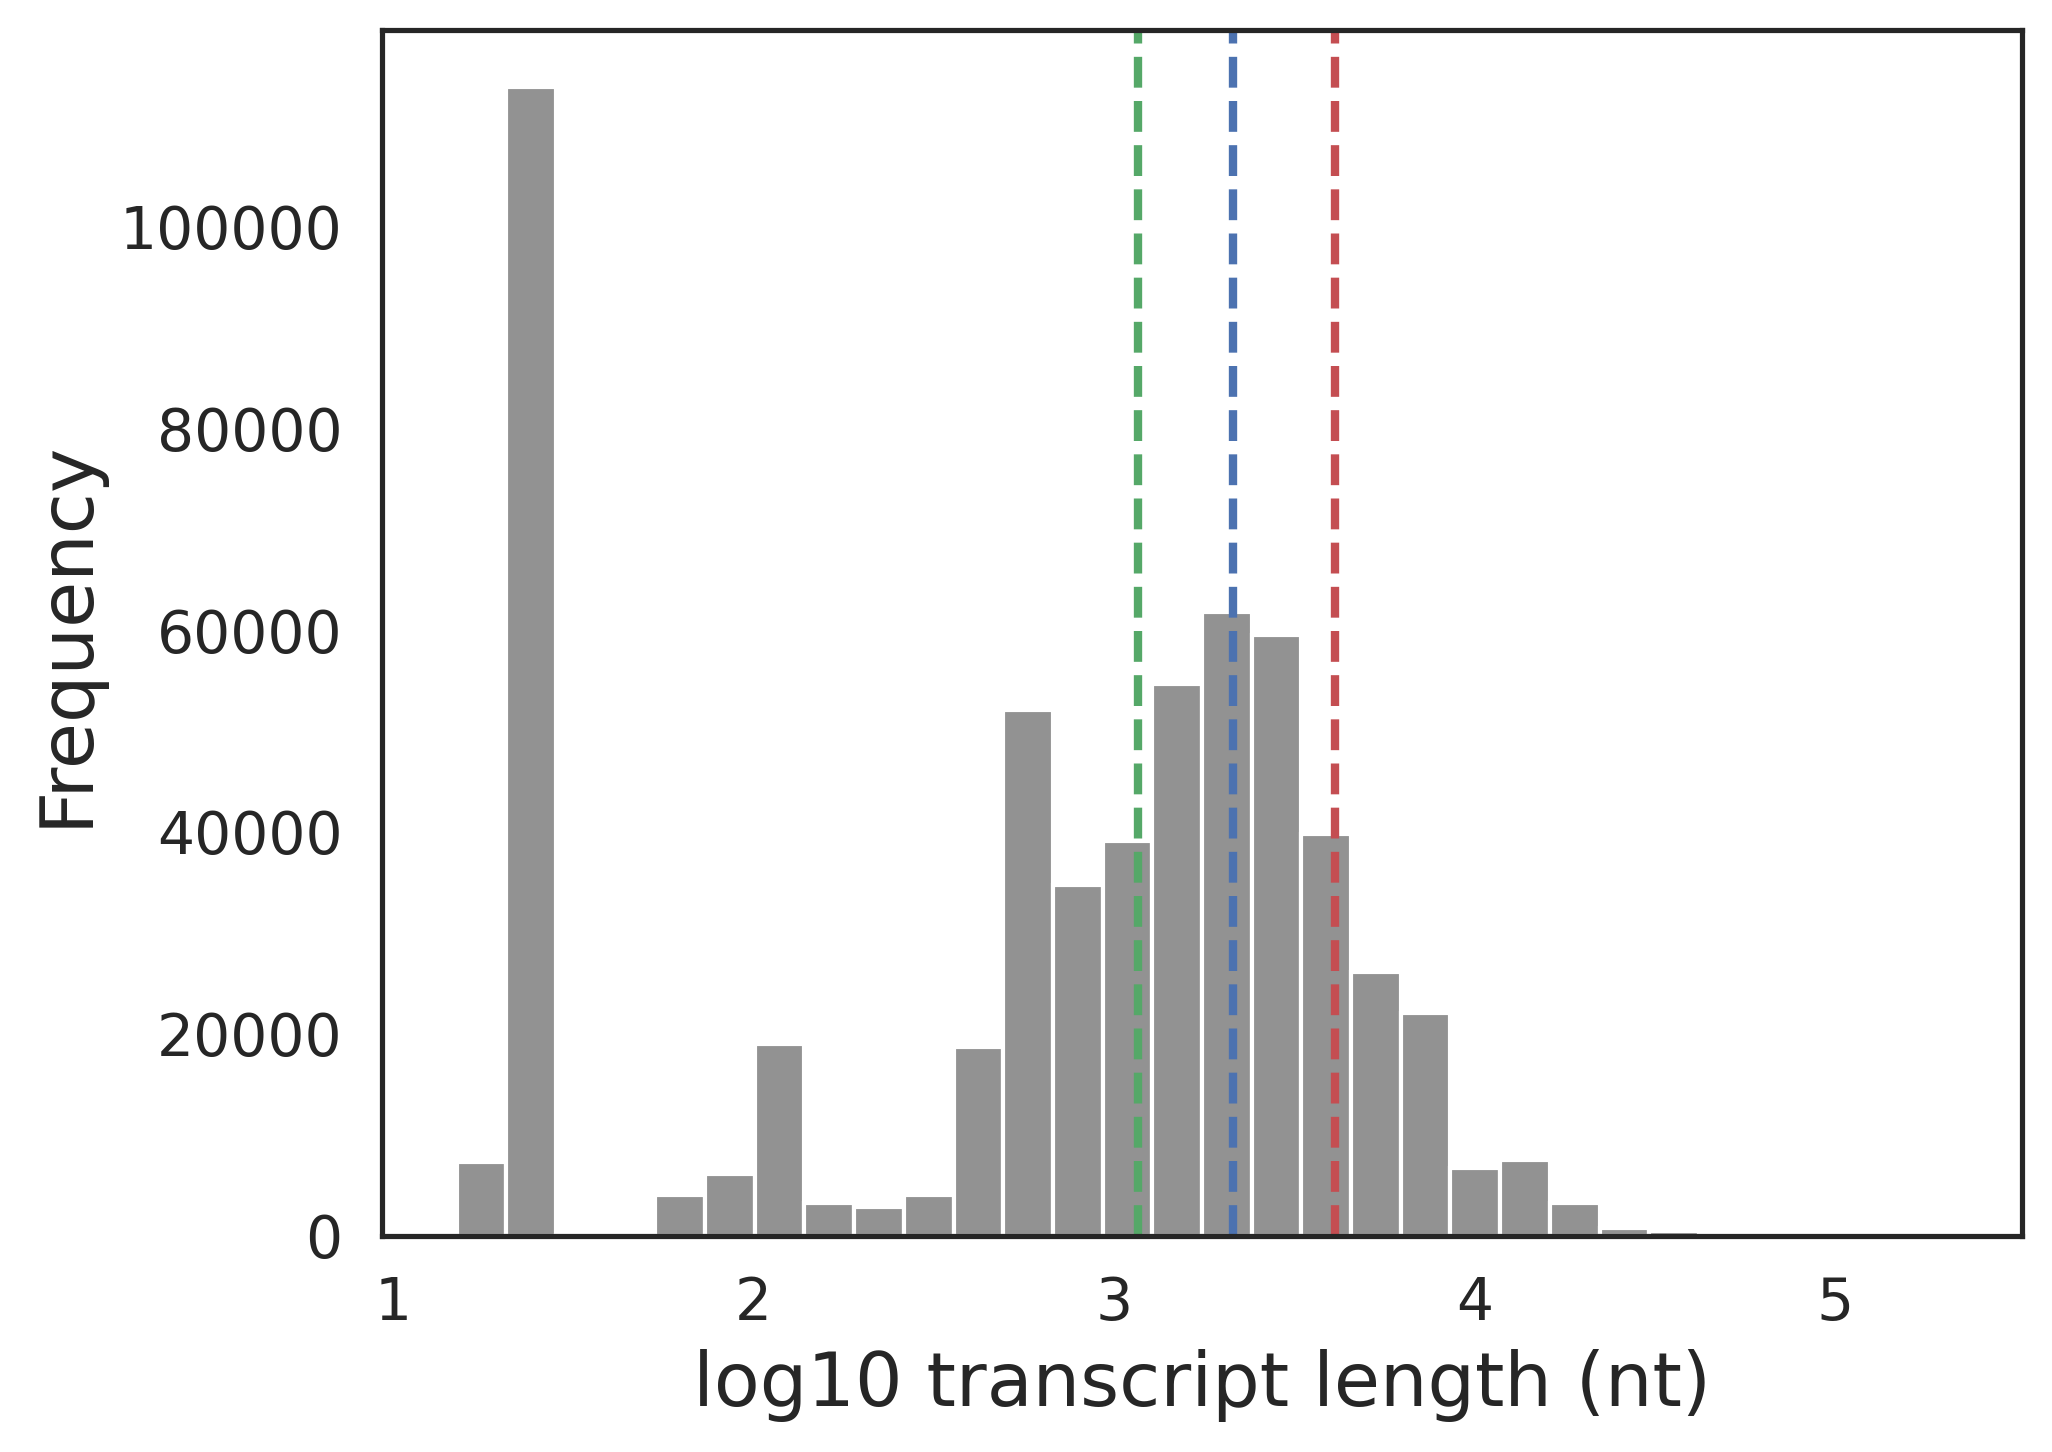

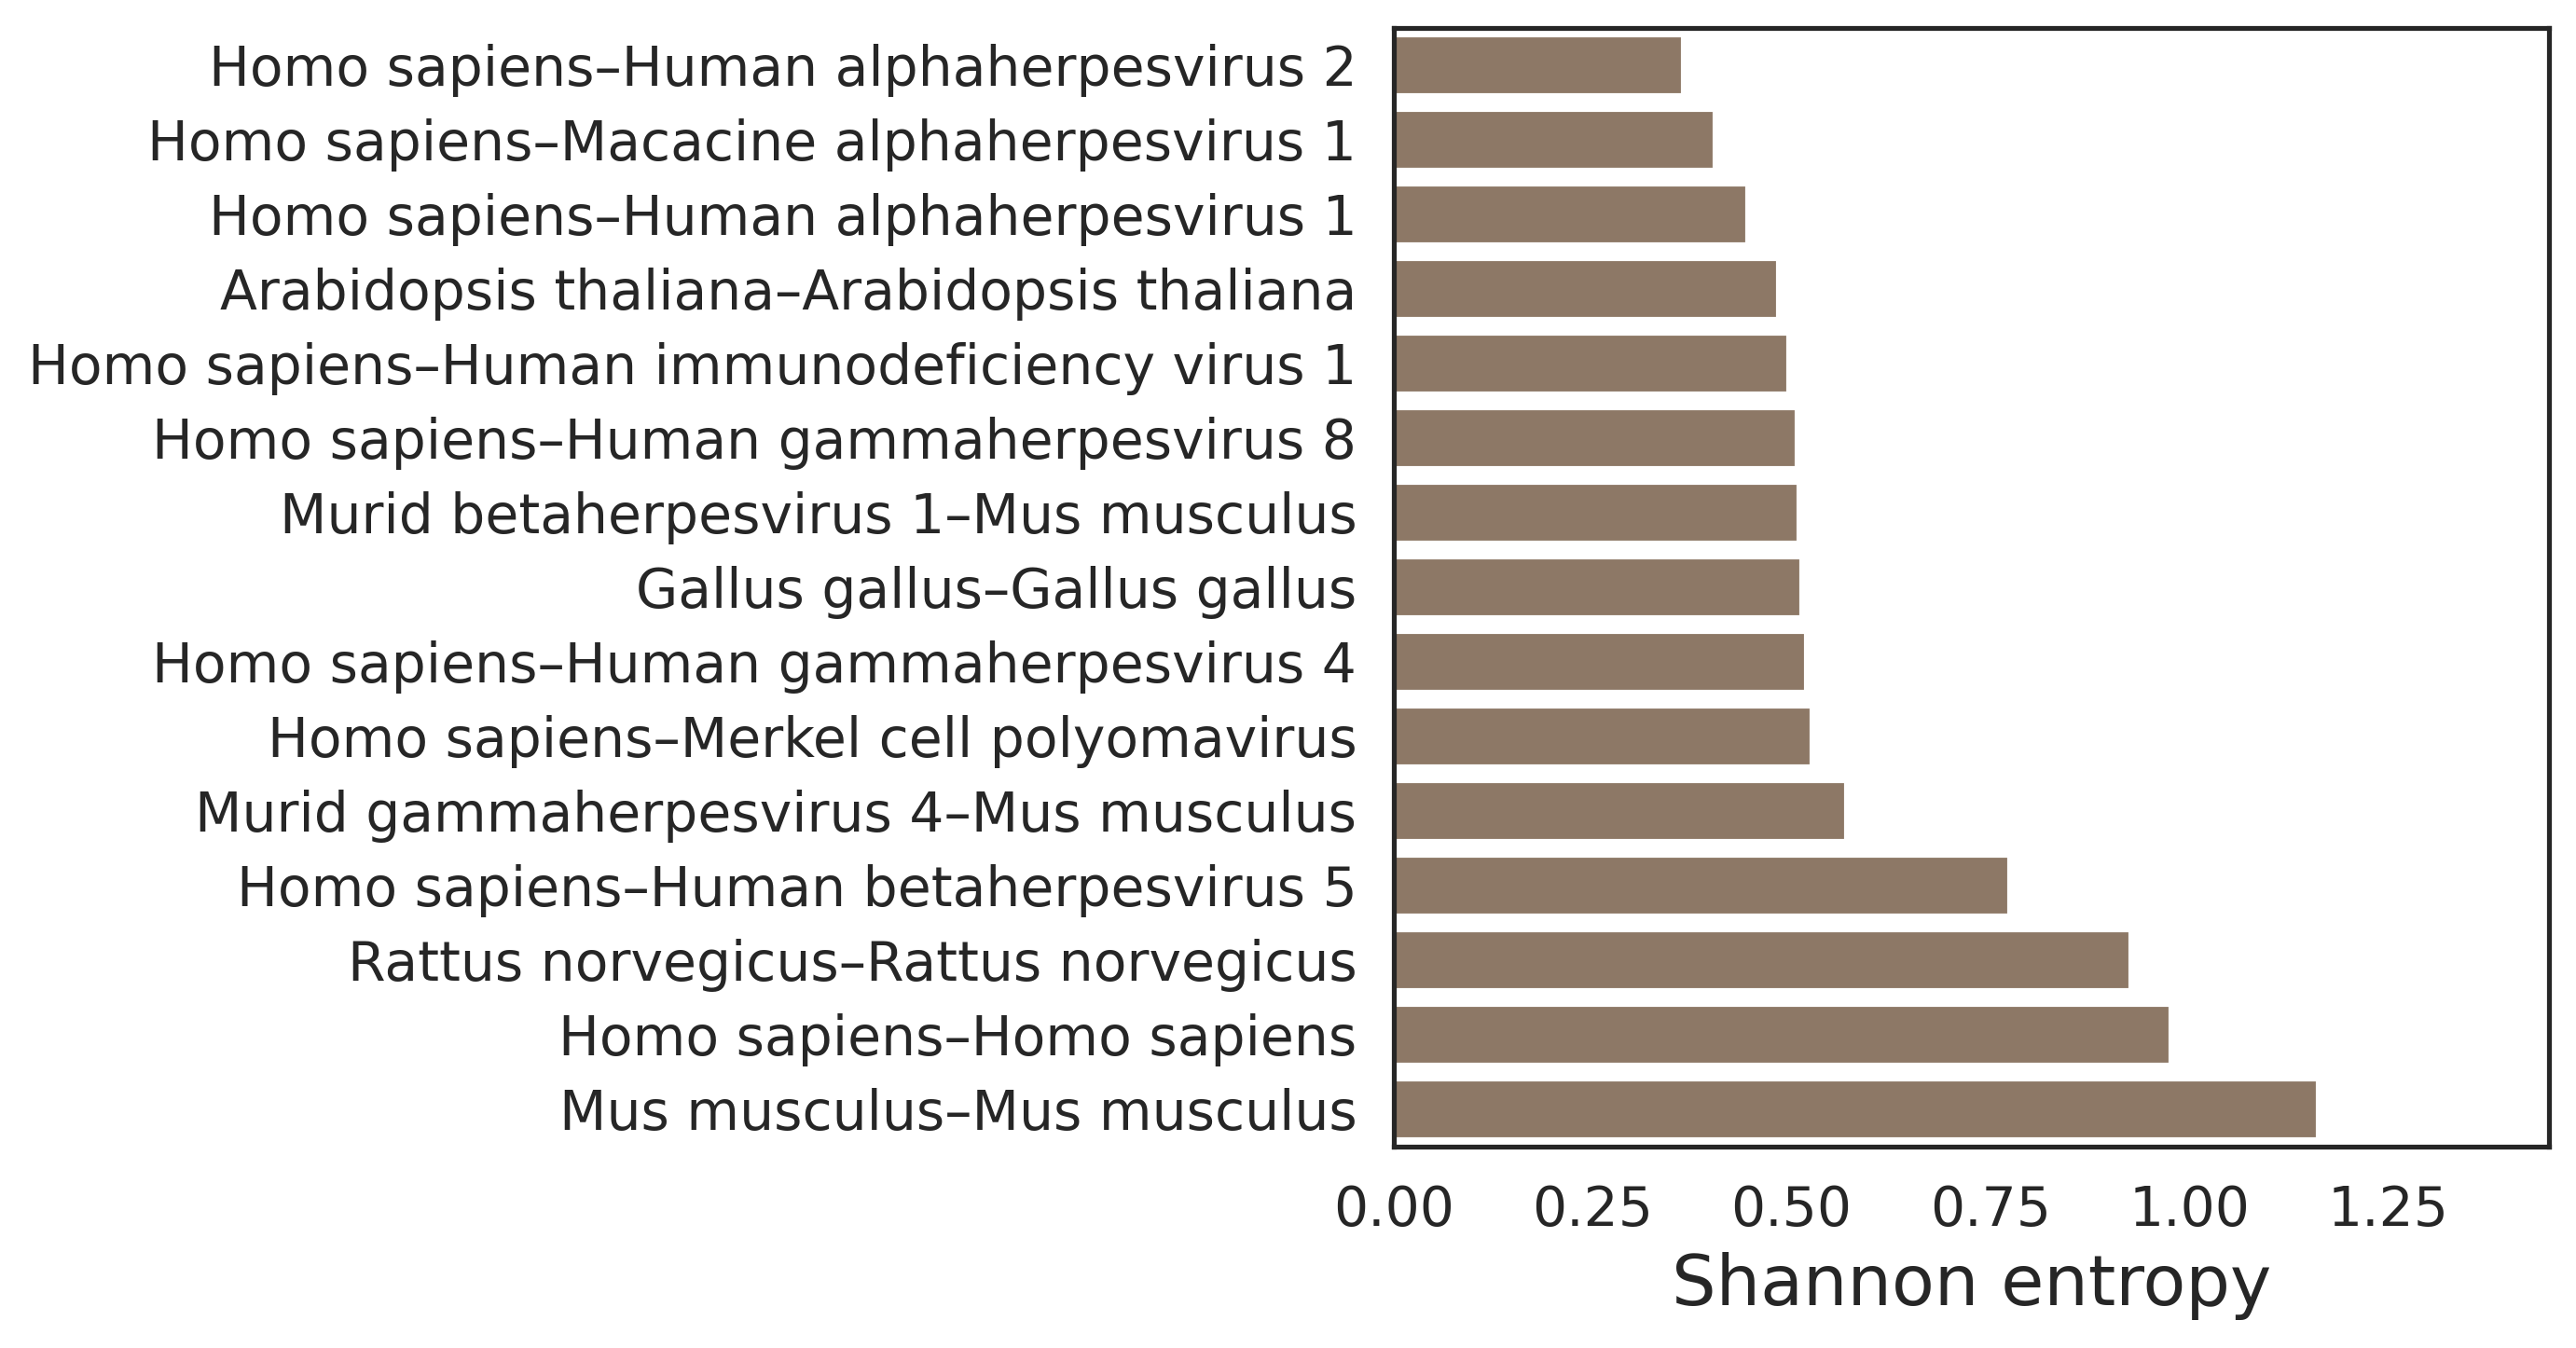

All figures saved as PDF.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.stats import entropy

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (6,4)

print("Shape:", df.shape)
df.head()


df["type_pair_unordered"] = df.apply(
    lambda x: tuple(sorted([x["Category1"], x["Category2"]])),
    axis=1
)

type_pair_counts = df["type_pair_unordered"].value_counts()

type_pair_counts.head(10)


df["species_pair_unordered"] = df.apply(
    lambda x: tuple(sorted([x["Species1"], x["Species2"]])),
    axis=1
)

def count_valid_seqs(x):
    if isinstance(x, list):
        return len([s for s in x if isinstance(s, str) and len(s) > 0])
    return 0

df["n_transcripts_total"] = (
    df["ent1_sequences"].apply(count_valid_seqs) +
    df["ent2_sequences"].apply(count_valid_seqs)
)

species_pair_counts = df["species_pair_unordered"].value_counts()
species_pair_counts.head(40)



# ==========================================
# RNA Interaction Dataset – Core Landscape
# Clean, reduced, publication-ready
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from scipy.stats import entropy

# ---------------------------
# Global style
# ---------------------------
mpl.rcParams.update({
    "figure.figsize": (7,5),
    "figure.dpi": 300,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif"
})

sns.set_style("white")

COLOR_TYPE = "#4C72B0"
COLOR_SPECIES = "#DD8452"
COLOR_TRANSCRIPT = "#55A868"
COLOR_LENGTH = "#6E6E6E"
COLOR_ANNOT = "#8172B3"
COLOR_ENTROPY = "#937860"

# ============================================================
# 1. Filtering
# ============================================================

type_counts = df["type_pair_unordered"].value_counts()
valid_types = type_counts[type_counts >= 100].index
df_f = df[df["type_pair_unordered"].isin(valid_types)].copy()

print("Final dataset size:", len(df_f))
print("Types retained:", df_f["type_pair_unordered"].nunique())
print("Species pairs retained:", df_f["species_pair_unordered"].nunique())

# ============================================================
# 2. Interaction Type Distribution (log scale)
# ============================================================

type_counts_f = df_f["type_pair_unordered"].value_counts().sort_values()

plt.figure()
sns.barplot(
    x=type_counts_f.values,
    y=[f"{a}–{b}" for a,b in type_counts_f.index],
    color=COLOR_TYPE
)
plt.xscale("log")
plt.xlim(1, type_counts_f.values.max() * 1.2)
plt.xlabel("Number of interactions (log scale)")
plt.tight_layout()
plt.savefig("data/ncrna_stats/Fig1_type_distribution.pdf")
plt.show()
plt.close()

# ============================================================
# 3. Species Interaction Landscape (Top 15)
# ============================================================

species_counts_f = (
    df_f["species_pair_unordered"]
    .value_counts()
    .head(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(7,5))

sns.barplot(
    x=species_counts_f.values,
    y=[f"{a}–{b}" for a,b in species_counts_f.index],
    color=COLOR_SPECIES,
    ax=ax
)

ax.set_xscale("log")

# add proper right margin buffer
max_val = species_counts_f.values.max()
ax.set_xlim(1, max_val * 1.5)

ax.set_xlabel("Number of interactions (log scale)")

# manually adjust margins (prevents right cutoff)
fig.subplots_adjust(left=0.35, right=0.95, top=0.95, bottom=0.15)

plt.savefig("data/ncrna_stats/Fig2_species_landscape.pdf", bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 4. Transcript Multiplicity
# ============================================================

# Median transcript multiplicity per type
transcript_median = (
    df_f.groupby("type_pair_unordered")["n_transcripts_total"]
    .median()
    .sort_values()
)

plt.figure()
sns.barplot(
    x=transcript_median.values,
    y=[f"{a}–{b}" for a,b in transcript_median.index],
    color="#C44E52"
)
plt.xlabel("Median transcripts per interaction")
plt.tight_layout()
plt.savefig("data/ncrna_stats/Fig3b_transcript_median_per_type.pdf")
plt.show()
plt.close()

# ============================================================
# 5. Transcript Length Distribution (log-scale)
# ============================================================

all_lengths = []

for lst in df_f["ent1_sequences"]:
    if isinstance(lst, list):
        all_lengths.extend([len(s) for s in lst if isinstance(s, str)])

for lst in df_f["ent2_sequences"]:
    if isinstance(lst, list):
        all_lengths.extend([len(s) for s in lst if isinstance(s, str)])

all_lengths = np.array(all_lengths)
all_lengths = all_lengths[all_lengths > 0]

mean_len = np.mean(all_lengths)
median_len = np.median(all_lengths)

plt.figure()
sns.histplot(
    np.log10(all_lengths),
    bins=30,
    color=COLOR_LENGTH
)

plt.axvline(np.log10(4096), color="#C44E52", linestyle="--", linewidth=2)
plt.axvline(np.log10(mean_len), color="#4C72B0", linestyle="--", linewidth=2)
plt.axvline(np.log10(median_len), color="#55A868", linestyle="--", linewidth=2)

plt.xlabel("log10 transcript length (nt)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("data/ncrna_stats/Fig4_transcript_length_log_distribution.pdf")
plt.show()
plt.close()


# ============================================================
# 7. Interaction-Type Diversity per Species
# ============================================================

entropy_values = []
species_list = species_counts_f.index

for sp in species_list:
    subset = df_f[df_f["species_pair_unordered"] == sp]
    counts = subset["type_pair_unordered"].value_counts()
    entropy_values.append(entropy(counts))

entropy_series = pd.Series(
    entropy_values,
    index=[f"{a}–{b}" for a,b in species_list]
).sort_values()

fig, ax = plt.subplots(figsize=(7,5))

sns.barplot(
    x=entropy_series.values,
    y=entropy_series.index,
    color=COLOR_ENTROPY,
    ax=ax
)

max_val = entropy_series.max()
ax.set_xlim(0, max_val * 1.25)  # more right padding
ax.set_xlabel("Shannon entropy")
ax.set_ylabel("")

# manual margin control (critical for NatComm-style large fonts)
fig.subplots_adjust(left=0.38, right=0.97, top=0.95, bottom=0.15)

plt.savefig("data/ncrna_stats/Fig7_species_entropy.pdf", bbox_inches="tight")
plt.show()
plt.close()


print("All figures saved as PDF.")


## GO terms
### Here we have two GO sources: RNAcentral and mygene API, we also need to check if the GO term from mygene is related to a ncRNA entity and remove protein coding GO-related IDs

In [39]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
from goatools.base import get_godag
from concurrent.futures import ProcessPoolExecutor, as_completed

# ------------------------------
# Load GO DAG
# ------------------------------
go_dag = get_godag("go-basic.obo", optional_attrs=["namespace", "alt_ids"])

# Precompute alt_id mapping for obsolete terms
alt_id_map = {}
for go_id, term in go_dag.items():
    for alt in getattr(term, "alt_ids", []):
        alt_id_map[alt] = term

# ------------------------------
# Functions
# ------------------------------
def extract_go_terms_mygene(entry):
    """Extract non-protein-coding GO IDs from MyGene JSON entry."""
    if entry is None:
        return []
    if entry.get("type_of_gene") == "protein_coding":
        return []
    go_dict = entry.get("go", {})
    terms = []
    for cat in ["BP", "MF", "CC"]:
        term_entry = go_dict.get(cat)
        if not term_entry:
            continue
        if isinstance(term_entry, list):
            terms.extend([t["id"] for t in term_entry if "id" in t])
        elif "id" in term_entry:
            terms.append(term_entry["id"])
    return terms

manual_go_map = {
    "GO:0007569": "BP",
    "GO:0016458": "BP"
}

def classify_go_with_alt(go_id, go_dag, alt_id_map):
    term = go_dag.get(go_id) or alt_id_map.get(go_id)
    if not term:
        # check manual mapping
        return manual_go_map.get(go_id, "Unknown")
    ns = getattr(term, "namespace", None)
    if ns == "biological_process":
        return "BP"
    if ns == "molecular_function":
        return "MF"
    if ns == "cellular_component":
        return "CC"
    return "Unknown"

def count_go_types(go_list, go_id_to_cat):
    counts = Counter()
    if not isinstance(go_list, list):
        return counts
    for go_id in go_list:
        if pd.isna(go_id):  # skip NA
            continue
        cat = go_id_to_cat.get(go_id, "Unknown")
        counts[cat] += 1
    return counts

def merge_go_terms_entity(row, entity_prefix):
    """Extract, deduplicate, and classify GO terms for a single entity."""
    rnacentral_go = row.get(f"{entity_prefix}_GO_RNAcentral", [])
    rnacentral_go = rnacentral_go if isinstance(rnacentral_go, list) else []

    mygene_go = extract_go_terms_mygene(row.get(f"{entity_prefix}_mygene_raw"))

    # Deduplicate & remove <NA>
    merged = list({go_id for go_id in rnacentral_go + mygene_go if pd.notna(go_id)})

    # Map to categories
    cat_map = {go_id: classify_go_with_alt(go_id, go_dag, alt_id_map) for go_id in merged}

    # Count per type
    type_counts = count_go_types(merged, cat_map)

    return merged, cat_map, type_counts

def process_row(row):
    ent1_results = merge_go_terms_entity(row, "ent1")
    ent2_results = merge_go_terms_entity(row, "ent2")
    return ent1_results, ent2_results

# ------------------------------
# Parallel processing
# ------------------------------
results = []
with ProcessPoolExecutor() as executor:
    futures = [executor.submit(process_row, row) for _, row in df.iterrows()]
    for f in as_completed(futures):
        results.append(f.result())

# Keep results in dataframe order
df["ent1_GO_combined"] = [r[0][0] for r in results]
df["ent1_GO_id_to_cat"] = [r[0][1] for r in results]
df["ent1_GO_type_counts"] = [r[0][2] for r in results]

df["ent2_GO_combined"] = [r[1][0] for r in results]
df["ent2_GO_id_to_cat"] = [r[1][1] for r in results]
df["ent2_GO_type_counts"] = [r[1][2] for r in results]

# ------------------------------
# Interaction-level GO presence stats
# ------------------------------
def go_presence_status(row):
    ent1_has = bool(row["ent1_GO_combined"])
    ent2_has = bool(row["ent2_GO_combined"])
    if ent1_has and ent2_has:
        return "both"
    elif ent1_has or ent2_has:
        return "one"
    else:
        return "none"

df["GO_interaction_status"] = df.apply(go_presence_status, axis=1)
interaction_stats = df["GO_interaction_status"].value_counts()
print("Interaction-level GO term presence stats:\n", interaction_stats)



  EXISTS: go-basic.obo
go-basic.obo: fmt(1.2) rel(2026-01-23) 42,036 Terms
Interaction-level GO term presence stats:
 GO_interaction_status
none    67195
one     43433
both     8737
Name: count, dtype: int64


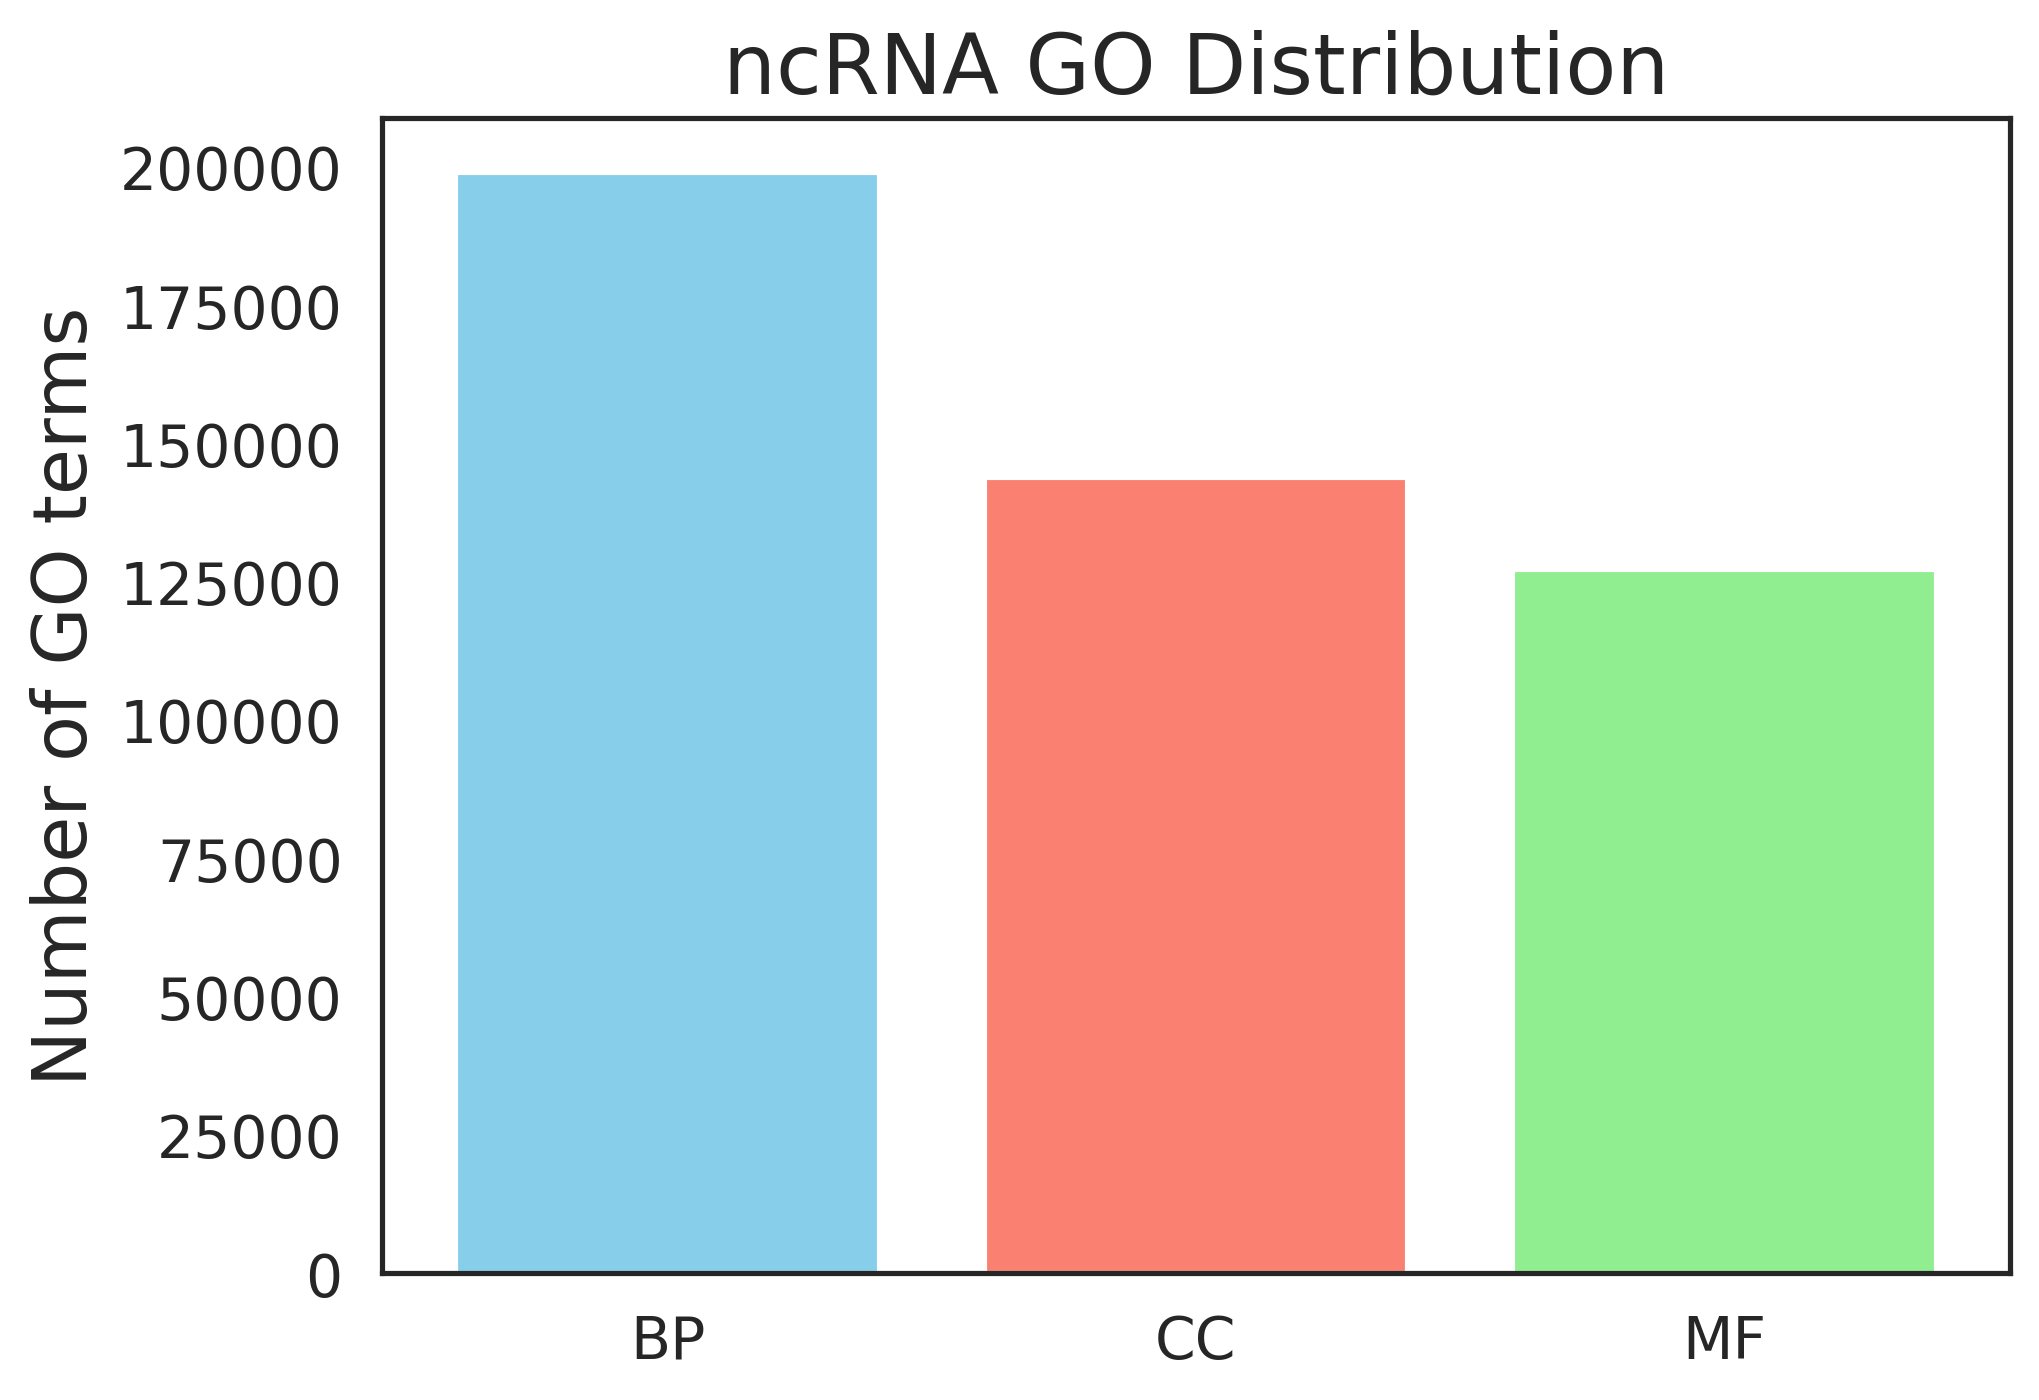

In [40]:
# ------------------------------
# Aggregate GO type counts across both entities
# ------------------------------
agg_counts = Counter()
for counts in df["ent1_GO_type_counts"]:
    agg_counts.update(counts)
for counts in df["ent2_GO_type_counts"]:
    agg_counts.update(counts)

plt.bar(agg_counts.keys(), agg_counts.values(), color=['skyblue', 'salmon', 'lightgreen'])
plt.ylabel("Number of GO terms")
plt.title("ncRNA GO Distribution")
plt.savefig("data/ncrna_stats/GO_distribution.pdf")
plt.show()

## rfam ids statistics

In [46]:
# ------------------------------
# Interaction-level Rfam presence stats
# ------------------------------
import pandas as pd
import numpy as np

def rfam_presence_status(row):
    # ent1_Rfam and ent2_Rfam are lists or <NA>
    ent1 = row.get("ent1_Rfam")
    ent2 = row.get("ent2_Rfam")
    
    ent1_has = bool(ent1) and not all(pd.isna(ent1))
    ent2_has = bool(ent2) and not all(pd.isna(ent2))
    
    if ent1_has and ent2_has:
        return "both"
    elif ent1_has or ent2_has:
        return "one"
    else:
        return "none"

df["Rfam_interaction_status"] = df.apply(rfam_presence_status, axis=1)
rfam_stats = df["Rfam_interaction_status"].value_counts()
print("Interaction-level Rfam presence stats:\n", rfam_stats)

Interaction-level Rfam presence stats:
 Rfam_interaction_status
none    96325
one     16442
both     6598
Name: count, dtype: int64


## entity extraction and transcrips analisys for entities with >1 transcripts

In [49]:
# ============================================================
# ncRNA ENTITY EXTRACTION (Entity-level, not transcript-level)
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Canonical entity key
# ------------------------------------------------------------

def make_entity_key(symbol, category, species, raw_id_list):
    raw_ids = tuple(sorted(raw_id_list)) if isinstance(raw_id_list, list) else tuple()
    return (symbol, category, species, raw_ids)

# ------------------------------------------------------------
# 2. Extract ncRNA entities from both interactors
# ------------------------------------------------------------

entities = []

for side in [1, 2]:

    symbol_col = f"Interactor{side}.Symbol"
    category_col = f"Category{side}"  # was Category{side}_std
    species_col = f"Species{side}"
    raw_id_col = f"Raw_ID{side}"  # was Raw_ID{side}_list
    seq_col = f"ent{side}_sequences"  # was seq{side}_list
    go_col = f"ent{side}_GO_RNAcentral"  # was GO{side}
    rfam_col = f"ent{side}_Rfam"  # was Rfam{side}
    bucket_col = f"ent{side}_ID_buckets"  # was ID_buckets{side}

    df_side = df[[
        symbol_col,
        category_col,
        species_col,
        raw_id_col,
        seq_col,
        go_col,
        rfam_col,
        bucket_col
    ]].copy()

    df_side.columns = [
        "symbol",
        "category",
        "species",
        "raw_ids",
        "seq_list",
        "GO",
        "Rfam",
        "ID_buckets"
    ]

    entities.append(df_side)

df_ncrna = pd.concat(entities, ignore_index=True)

print("Total ncRNA entries (with duplicates):", len(df_ncrna))

# ------------------------------------------------------------
# 3. Deduplicate entities using canonical key
# ------------------------------------------------------------

df_ncrna["entity_key"] = df_ncrna.apply(
    lambda x: make_entity_key(
        x["symbol"],
        x["category"],
        x["species"],
        x["raw_ids"]
    ),
    axis=1
)

df_ncrna_unique = (
    df_ncrna
    .drop_duplicates(subset="entity_key")
    .reset_index(drop=True)
)

print("Unique ncRNA entities:", len(df_ncrna_unique))

# ------------------------------------------------------------
# 4. Transcript-level statistics per entity
# ------------------------------------------------------------

def valid_sequences(lst):
    if isinstance(lst, list):
        return [s for s in lst if isinstance(s, str) and len(s) > 0]
    return []

def count_annotations(lst):
    if isinstance(lst, list):
        return len([v for v in lst if pd.notna(v)])
    return 0

df_ncrna_unique["n_transcripts"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: len(valid_sequences(x)))
)

df_ncrna_unique["mean_transcript_length"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: np.mean([len(s) for s in valid_sequences(x)])
           if len(valid_sequences(x)) > 0 else np.nan)
)

df_ncrna_unique["median_transcript_length"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: np.median([len(s) for s in valid_sequences(x)])
           if len(valid_sequences(x)) > 0 else np.nan)
)

df_ncrna_unique["max_transcript_length"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: np.max([len(s) for s in valid_sequences(x)])
           if len(valid_sequences(x)) > 0 else np.nan)
)

# ------------------------------------------------------------
# 5. Functional annotation depth
# ------------------------------------------------------------

df_ncrna_unique["n_GO"] = df_ncrna_unique["GO"].apply(count_annotations)
df_ncrna_unique["n_Rfam"] = df_ncrna_unique["Rfam"].apply(count_annotations)

# ------------------------------------------------------------
# 6. Basic dataset diagnostics
# ------------------------------------------------------------

print("\nCategory distribution:")
print(df_ncrna_unique["category"].value_counts())

print("\nSpecies distribution (top 10):")
print(df_ncrna_unique["species"].value_counts().head(10))

print("\nTranscript count summary:")
print(df_ncrna_unique["n_transcripts"].describe())

print("\nTranscript length summary:")
print(df_ncrna_unique["mean_transcript_length"].describe())

# ------------------------------------------------------------
# 7. Save final dataset
# ------------------------------------------------------------

df_ncrna_unique.to_pickle("ncrna_entities_final.pkl")

print("\nSaved: ncrna_entities_final.pkl")

Total ncRNA entries (with duplicates): 238730
Unique ncRNA entities: 14477

Category distribution:
category
lncRNA                  7477
miRNA                   4962
pseudo                   795
snoRNA                   744
circRNA                  186
snRNA                    175
rRNA                      89
scaRNA                    22
tRNA                      18
ncRNA                      7
ribozyme                   1
processed_transcript       1
Name: count, dtype: int64

Species distribution (top 10):
species
Homo sapiens                10028
Mus musculus                 3810
Gallus gallus                 173
Arabidopsis thaliana          133
Rattus norvegicus              84
Human gammaherpesvirus 4       44
Human alphaherpesvirus 1       26
Human betaherpesvirus 5        25
Human gammaherpesvirus 8       25
Human alphaherpesvirus 2       22
Name: count, dtype: int64

Transcript count summary:
count    14477.000000
mean         2.496443
std          7.814119
min          1.0000

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import pandas as pd

# -----------------------------
# Global plotting style
# -----------------------------
mpl.rcParams.update({
    "figure.figsize": (7,5),
    "figure.dpi": 300,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"]
})
sns.set_style("white")
PASTEL_COLOR = "#A6CEE3"

# -----------------------------
# Bin function
# -----------------------------
def transcript_bin(n):
    if n == 1:
        return "1"
    elif n == 2:
        return "2"
    elif 3 <= n <= 5:
        return "3–5"
    elif 6 <= n <= 10:
        return "6–10"
    else:
        return ">10"

bin_order = ["1", "2", "3–5", "6–10", ">10"]

# -----------------------------
# Step 1 — count valid sequences only
# -----------------------------
df_step1 = df_ncrna_unique.copy()
df_step1["seq_list_valid"] = df_step1["seq_list"].apply(
    lambda x: [s for s in x if isinstance(s, str)] if isinstance(x, list) else []
)
df_step1["n_transcripts_orig"] = df_step1["seq_list_valid"].apply(len)
df_step1["transcript_bin_orig"] = df_step1["n_transcripts_orig"].apply(transcript_bin)

bin_counts_step1 = df_step1["transcript_bin_orig"].value_counts().reindex(bin_order, fill_value=0)
bin_counts_step1.name = "count"
print("\nStep 1 — Original counts:\n", bin_counts_step1)

# Step 2 — filter long sequences from valid sequences
MAX_TRANSCRIPT_LEN = 1000000
df_step2 = df_step1.copy()

# Filter sequences
df_step2["seq_list_filtered"] = df_step2["seq_list_valid"].apply(lambda x: [s for s in x if len(s) <= MAX_TRANSCRIPT_LEN])

# Count only sequences that survived filtering
df_step2["n_transcripts_filtered"] = df_step2["seq_list_filtered"].apply(len)

# Only bin entities with at least 1 sequence
df_step2["transcript_bin_filtered"] = df_step2["n_transcripts_filtered"].apply(lambda n: transcript_bin(n) if n > 0 else "0")

# Optional: remove 0 for plotting
bin_order_step2 = ["1", "2", "3–5", "6–10", ">10"]
bin_counts_step2 = df_step2[df_step2["n_transcripts_filtered"] > 0]["transcript_bin_filtered"].value_counts().reindex(bin_order_step2, fill_value=0)
bin_counts_step2.name = "count"
print("\nStep 2 — Counts afterfilter for seq len:\n", bin_counts_step2)

# -----------------------------
# Step 3 — keep entities with >=2 transcripts
# -----------------------------
df_step3 = df_step2[df_step2["n_transcripts_filtered"] >= 2].copy()
df_step3["transcript_bin_multi"] = df_step3["n_transcripts_filtered"].apply(transcript_bin)

bin_counts_step3 = df_step3["transcript_bin_multi"].value_counts().reindex(bin_order, fill_value=0)
bin_counts_step3 = bin_counts_step3.drop("1")  # Bin 1 removed
bin_counts_step3.name = "count"
print("\nStep 3 — Counts after keeping entities with ≥2 transcripts:\n", bin_counts_step3)


Step 1 — Original counts:
 transcript_bin_orig
1       10216
2        1719
3–5      1621
6–10      448
>10       473
Name: count, dtype: int64

Step 2 — Counts afterfilter for seq len:
 transcript_bin_filtered
1       10216
2        1719
3–5      1621
6–10      448
>10       473
Name: count, dtype: int64

Step 3 — Counts after keeping entities with ≥2 transcripts:
 transcript_bin_multi
2       1719
3–5     1621
6–10     448
>10      473
Name: count, dtype: int64


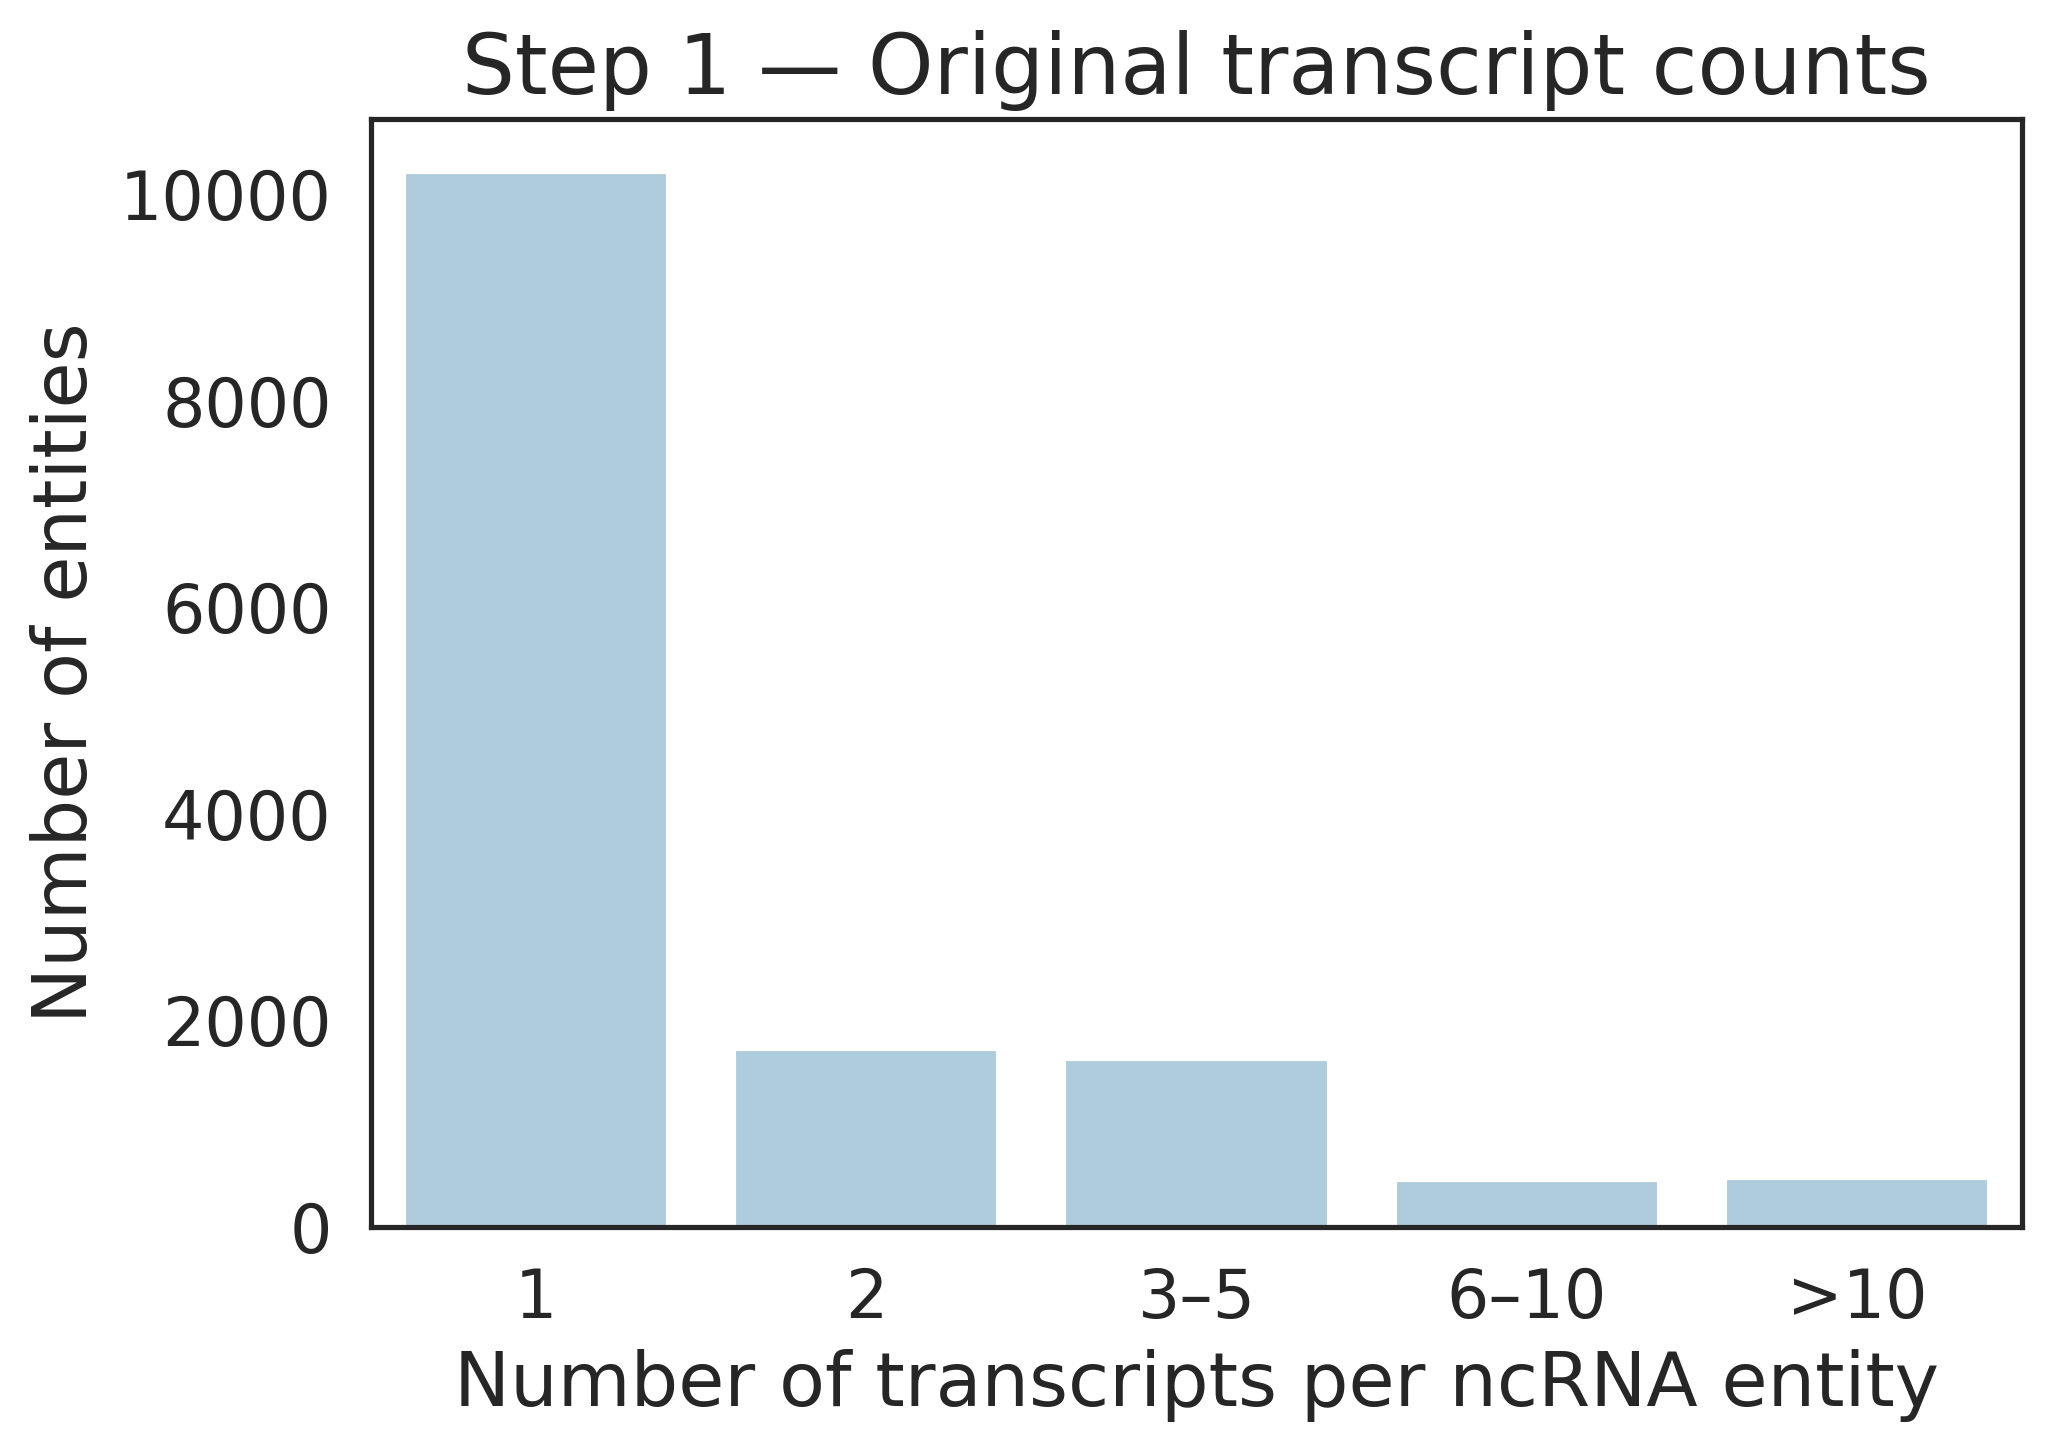

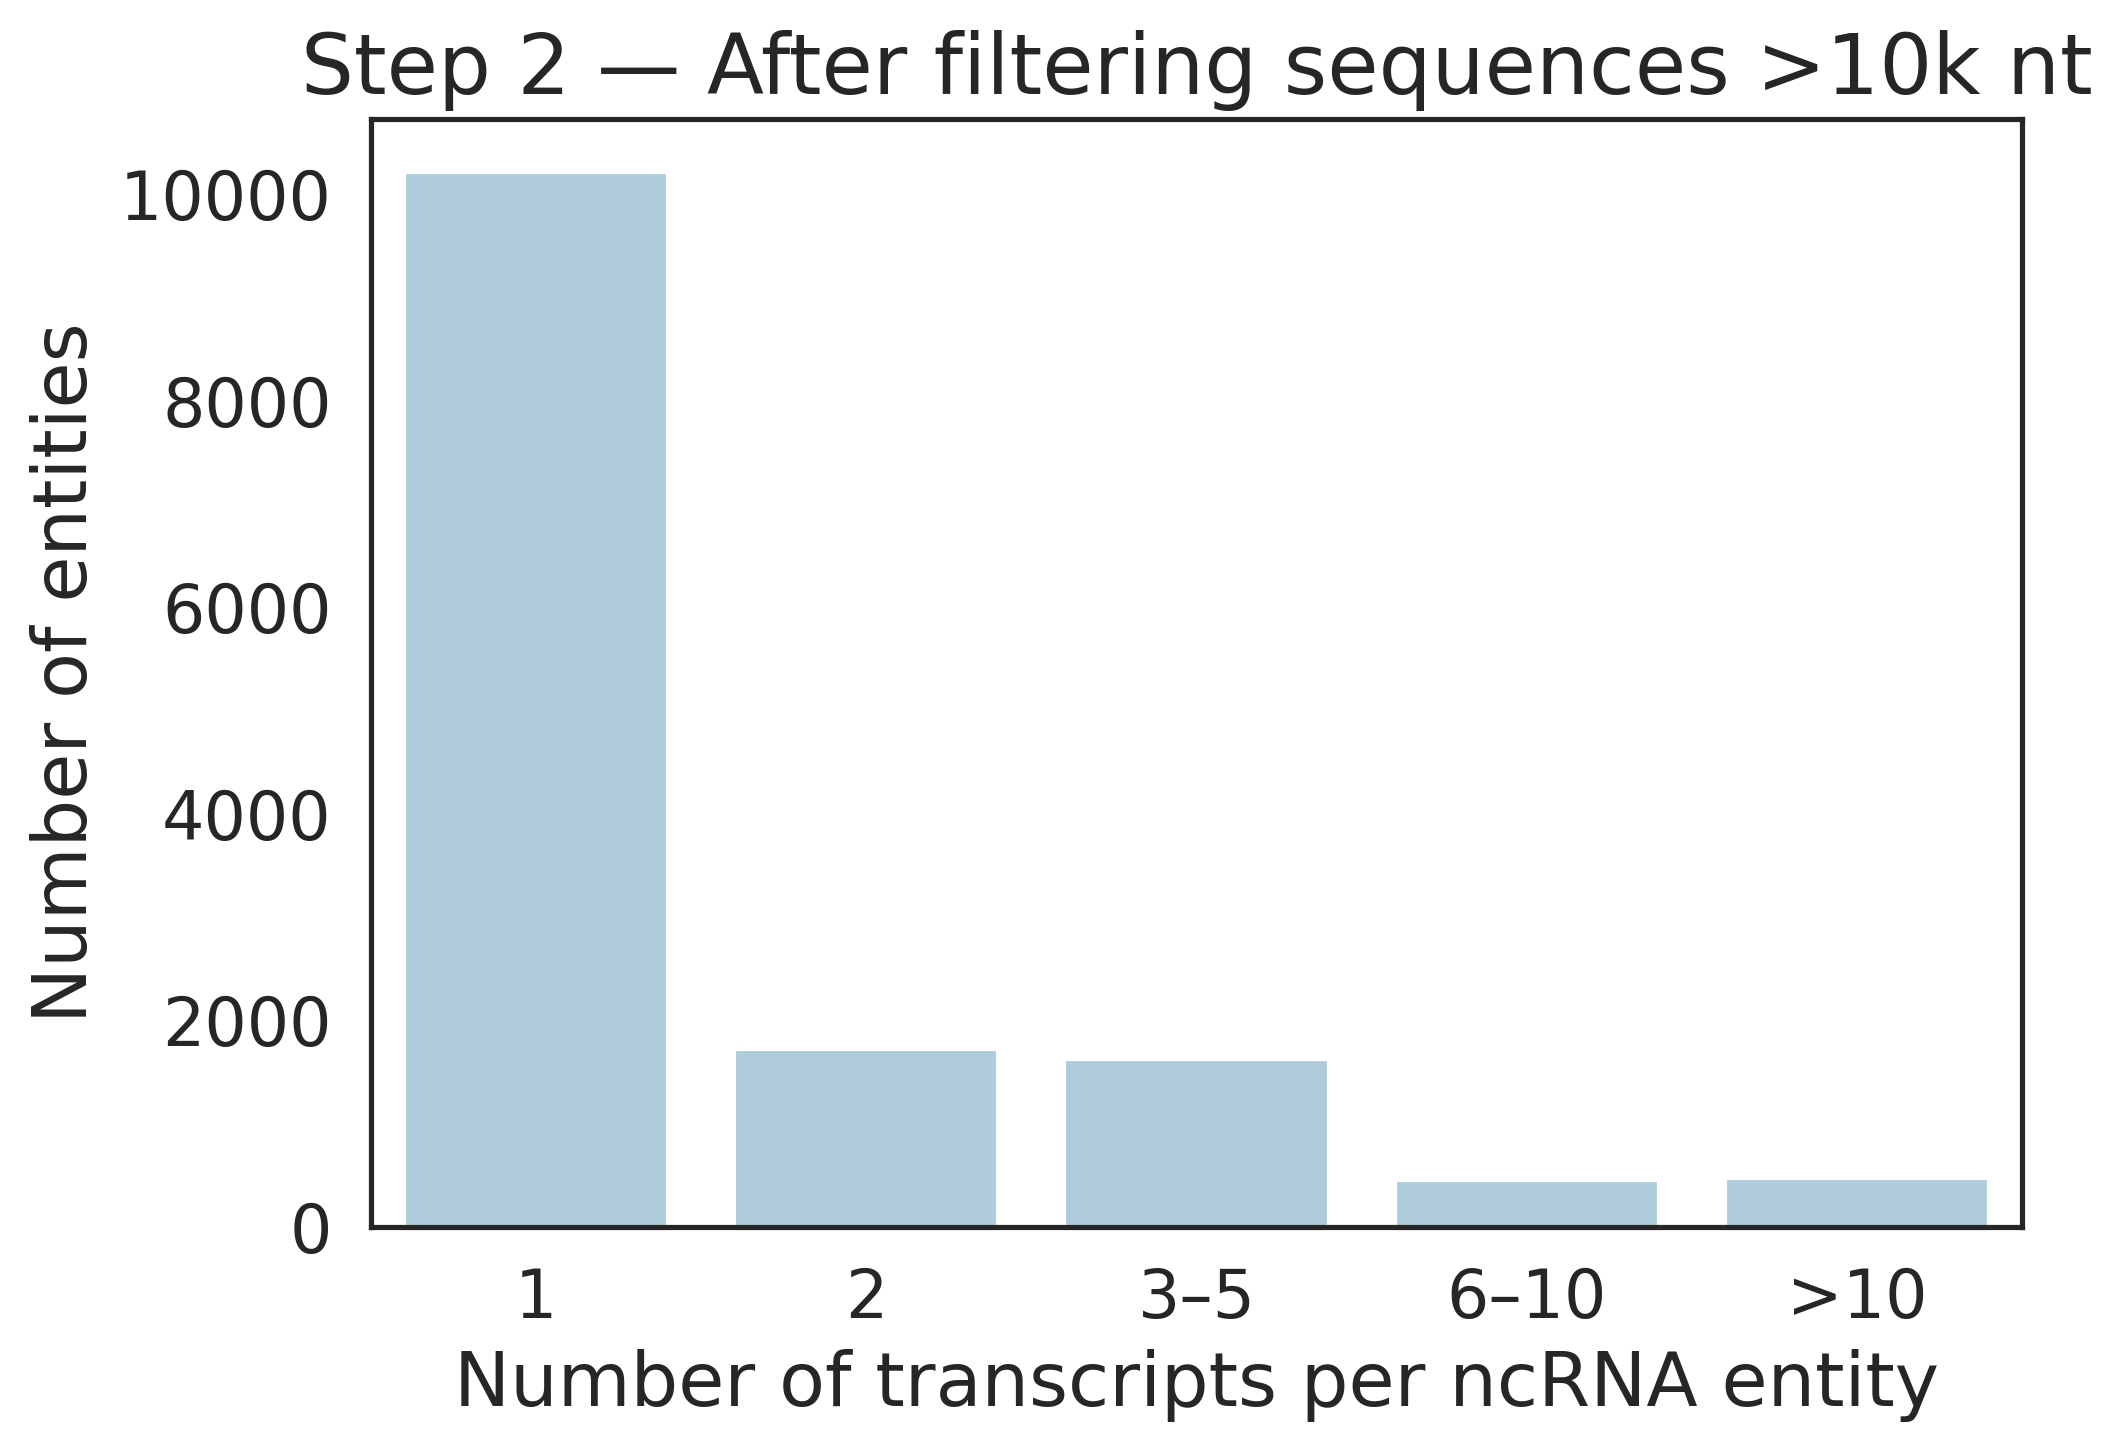

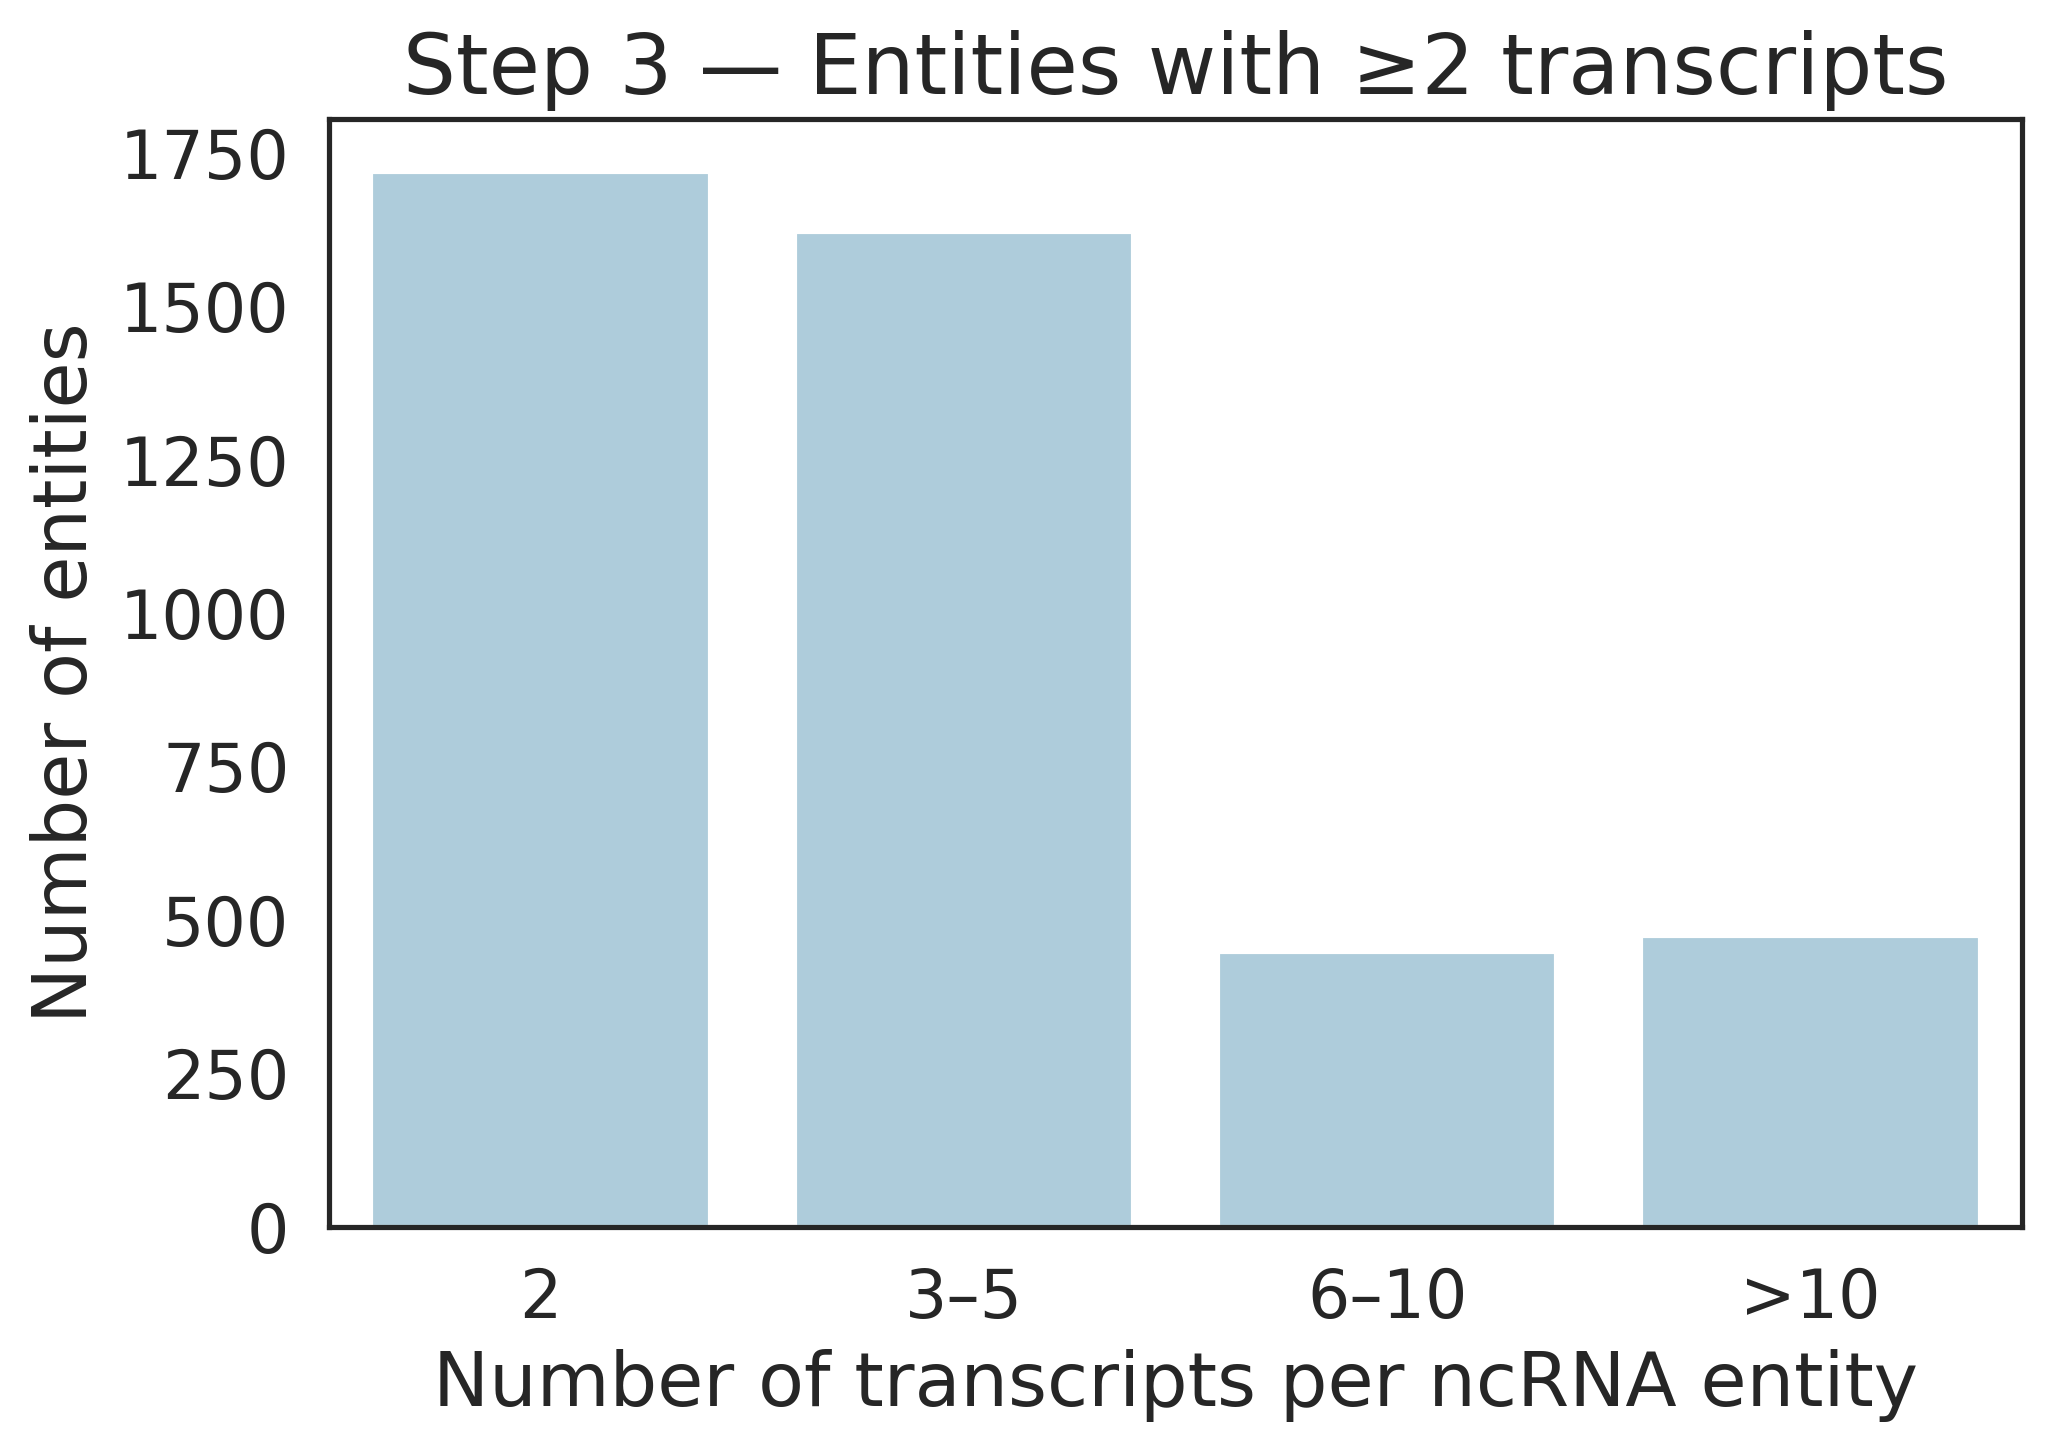

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

PASTEL_COLOR = "#A6CEE3"
sns.set_style("white")

bin_labels = ["1", "2", "3–5", "6–10", ">10"]

# -----------------------------
# Step 1 histogram based on bins
# -----------------------------
counts_step1 = df_step1["transcript_bin_orig"].value_counts().reindex(bin_labels, fill_value=0)
plt.figure(figsize=(7,5), dpi=300)
sns.barplot(x=counts_step1.index, y=counts_step1.values, color=PASTEL_COLOR)
plt.xlabel("Number of transcripts per ncRNA entity")
plt.ylabel("Number of entities")
plt.title("Step 1 — Original transcript counts")
plt.tight_layout()
plt.savefig("data/ncrna_stats/transcripts_counts.pdf")
plt.show()

# -----------------------------
# Step 2 histogram based on bins
# -----------------------------
counts_step2 = df_step2[df_step2["n_transcripts_filtered"]>0]["transcript_bin_filtered"].value_counts().reindex(bin_labels, fill_value=0)
plt.figure(figsize=(7,5), dpi=300)
sns.barplot(x=counts_step2.index, y=counts_step2.values, color=PASTEL_COLOR)
plt.xlabel("Number of transcripts per ncRNA entity")
plt.ylabel("Number of entities")
plt.title("Step 2 — After filtering sequences >10k nt")
plt.tight_layout()
plt.show()

# -----------------------------
# Step 3 histogram based on bins
# -----------------------------
counts_step3 = df_step3["transcript_bin_multi"].value_counts().reindex(bin_labels[1:], fill_value=0)  # remove "1"
plt.figure(figsize=(7,5), dpi=300)
sns.barplot(x=counts_step3.index, y=counts_step3.values, color=PASTEL_COLOR)
plt.xlabel("Number of transcripts per ncRNA entity")
plt.ylabel("Number of entities")
plt.title("Step 3 — Entities with ≥2 transcripts")
plt.tight_layout()
plt.show()

In [ ]:
from itertools import combinations
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
import multiprocessing

# -----------------------------
# 1. Global identity (Needleman–Wunsch, globalxx)
# -----------------------------

from Bio.Align import PairwiseAligner

# -----------------------------
# 1. Global identity using PairwiseAligner
# -----------------------------
aligner = PairwiseAligner()
aligner.mode = 'global'
aligner.match_score = 1
aligner.mismatch_score = 0
aligner.open_gap_score = 0
aligner.extend_gap_score = 0

def global_identity(seq1, seq2):
    # Compute global alignment score
    score = aligner.score(seq1, seq2)
    # Normalize by length of alignment (max length)
    max_len = max(len(seq1), len(seq2))
    return score / max_len

# -----------------------------
# 2. Per-entity similarity statistics
# -----------------------------
def transcript_similarity_stats(seq_list):
    # Only valid sequences
    seqs = [s for s in seq_list if isinstance(s, str) and len(s) > 0]

    if len(seqs) < 2:
        return {
            "n_pairs": 0,
            "mean_sim": np.nan,
            "median_sim": np.nan,
            "min_sim": np.nan,
            "max_sim": np.nan,
            "var_sim": np.nan
        }

    sims = [global_identity(s1, s2) for s1, s2 in combinations(seqs, 2)]
    sims = np.array(sims)

    return {
        "n_pairs": len(sims),
        "mean_sim": sims.mean(),
        "median_sim": np.median(sims),
        "min_sim": sims.min(),
        "max_sim": sims.max(),
        "var_sim": sims.var()
    }

# -----------------------------
# 3. Parallel execution on Step 3 entities
# -----------------------------
n_cores = multiprocessing.cpu_count()

# Use df_step3 and the filtered seq_list
results = Parallel(n_jobs=n_cores)(
    delayed(transcript_similarity_stats)(seqs)
    for seqs in df_step3["seq_list_filtered"]
)

results_df = pd.DataFrame(results)

# Attach similarity statistics to df_step3
df_step3 = pd.concat(
    [df_step3.reset_index(drop=True), results_df],
    axis=1
)

print("Similarity computation complete.")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

PASTEL_SIM = "#B2DF8A"
PASTEL_BOX = "#FDBF6F"
sns.set_style("white")

# --------------------------------------
# 1. Histogram of mean pairwise identity
# --------------------------------------
plt.figure(figsize=(7,5), dpi=300)
sns.histplot(df_step3["mean_sim"].dropna(), bins=30, color=PASTEL_SIM)
plt.xlabel("Mean pairwise transcript identity")
plt.ylabel("Number of RNA entities")
plt.title("Distribution of mean transcript identity")
plt.tight_layout()
plt.savefig("data/ncrna_stats/transcript_pairwise_id.pdf")
plt.show()
plt.close()

# --------------------------------------
# 2. Boxplot of similarity by transcript multiplicity bins
# --------------------------------------
# Only bins "2", "3–5", "6–10", ">10"
bins_order = ["2", "3–5", "6–10", ">10"]
plt.figure(figsize=(8,5), dpi=300)
sns.boxplot(
    x="transcript_bin_multi",
    y="mean_sim",
    data=df_step3,
    order=bins_order,
    color=PASTEL_BOX
)
plt.xlabel("Transcript multiplicity bin")
plt.ylabel("Mean pairwise identity")
plt.title("Transcript identity vs transcript multiplicity")
plt.tight_layout()
plt.savefig("data/ncrna_stats/transcript_multiplicity_bin.pdf")
plt.show()
plt.close()

# --------------------------------------
# 3. Scatter: number of pairs vs mean similarity
# --------------------------------------
df_step3["log_n_pairs"] = np.log10(df_step3["n_pairs"] + 1)  # avoid log(0)
plt.figure(figsize=(7,5), dpi=300)
sns.scatterplot(
    x="log_n_pairs",
    y="mean_sim",
    hue="transcript_bin_multi",
    palette="Set2",
    data=df_step3,
    alpha=0.7
)
plt.xlabel("log10(number of transcript pairs + 1)")
plt.ylabel("Mean pairwise identity")
plt.title("Mean identity vs number of transcript pairs")
plt.legend(title="Transcript bin")
plt.tight_layout()
plt.savefig("data/ncrna_stats/transcript_id_vs_pairs.pdf")
plt.show()
plt.close()


In [ ]:
# --------------------------------------
# Summary statistics across all entities
# --------------------------------------
print("=== Overall transcript similarity statistics ===")
print("Number of entities:", len(df_step3))
print("Mean of mean_sim:", df_step3["mean_sim"].mean())
print("Median of mean_sim:", df_step3["mean_sim"].median())
print("Min/Max mean_sim:", df_step3["mean_sim"].min(), df_step3["mean_sim"].max())
print("Mean of var_sim:", df_step3["var_sim"].mean())
print("Median of var_sim:", df_step3["var_sim"].median())
print("Min/Max var_sim:", df_step3["var_sim"].min(), df_step3["var_sim"].max())
print("Mean number of transcript pairs per entity:", df_step3["n_pairs"].mean())
print("Median number of transcript pairs per entity:", df_step3["n_pairs"].median())
print()

# --------------------------------------
# Summary per transcript multiplicity bin
# --------------------------------------
print("=== Transcript similarity statistics by multiplicity bin ===")
bins_order = ["2", "3–5", "6–10", ">10"]
for b in bins_order:
    sub = df_step3[df_step3["transcript_bin_multi"] == b]
    print(f"Bin '{b}': n_entities={len(sub)}")
    print(f"  mean mean_sim: {sub['mean_sim'].mean():.3f}")
    print(f"  median mean_sim: {sub['mean_sim'].median():.3f}")
    print(f"  mean var_sim: {sub['var_sim'].mean():.4f}")
    print(f"  median var_sim: {sub['var_sim'].median():.4f}")
    print(f"  mean n_pairs: {sub['n_pairs'].mean():.1f}")
    print(f"  median n_pairs: {sub['n_pairs'].median():.1f}")
    print()

In [ ]:
# Define threshold
SIM_THRESHOLD = 0.5

# Count entities that would be removed
n_total = len(df_step3)
n_removed = (df_step3["mean_sim"] < SIM_THRESHOLD).sum()
n_kept = n_total - n_removed

print(f"Total entities: {n_total}")
print(f"Entities below mean_sim {SIM_THRESHOLD}: {n_removed} ({n_removed/n_total:.1%})")
print(f"Entities above mean_sim {SIM_THRESHOLD}: {n_kept} ({n_kept/n_total:.1%})")